# Confiabilidad y Planeación de Capacidad — Andes Vision AI

**Versión Colab: código incorporado; no requiere una carpeta src externa. Requiere los CSV y las bibliotecas indicadas.**

**C1:** 1137978133. **C2:** 1141914189. **Semilla:** 2279892322.

| Parámetro | Valor | Parámetro | Valor |
|---|---:|---|---:|
| Umbral SLO τ | 190 ms | Tolerancia ε | 0,02 |
| Confianza | 95 % | Crecimiento g | 1,5 |
| Límite t₁ | 100 KB | Límite t₂ | 450 KB |
| Prevalencia π | 0,008 | kₘáₓ | 6 |
| Desplazamiento r | 4 | Solicitudes N | 14 |

**Datos:** el grupo confirmó que los CSV suministrados corresponden a estas identificaciones. La segmentación debe revisarse si los CSV cambian.


**Contexto del bloque.** Importa las bibliotecas básicas, calcula la semilla a partir de las dos identificaciones y deriva los parámetros del grupo. Su objetivo es fijar una configuración reproducible para las secciones siguientes.

In [1]:
import numpy as np
import pandas as pd
import warnings
from IPython.display import display, Image, Markdown
from contextlib import redirect_stdout
from io import StringIO

warnings.filterwarnings("ignore", category=FutureWarning, message="As of SciPy 1.17.*")
C1, C2 = 1137978133, 1141914189
S = C1 + C2
rng = np.random.default_rng(S)
nivel_confianza = {0: 0.90, 1: 0.95, 2: 0.99}[S % 3]
tau_ms, epsilon = 180 + 10 * (S % 9), 0.01 * (1 + S % 3)
g = 1.4 + 0.1 * (S % 7)
t1_kb, t2_kb = 80 + 10 * (S % 5), 400 + 25 * (S % 5)
pi, k_max, r, N = (4 + S % 6) / 1000, 4 + S % 5, S % 6, 10 + S % 11
pd.set_option("display.precision", 4)
pd.set_option("display.float_format", lambda x: f"{x:.4g}")


## Preparación de datos y código

En Google Colab, la siguiente celda solicita autorización y busca los tres CSV por el identificador de la carpeta compartida del grupo, incluyendo sus subcarpetas. La cuenta elegida debe tener acceso a la carpeta. Si hay archivos duplicados con el mismo nombre, la ejecución se detiene para evitar seleccionar datos equivocados.

El código de análisis está incorporado en este cuaderno. Los CSV descargados se almacenan en un directorio temporal y los archivos de Drive no se modifican. Para ejecutar fuera de Colab, cambie `FUENTE_DATOS` a `"local"` y coloque los archivos en `data/raw/` o indique `CARPETA_LOCAL`. Las salidas se guardan en una carpeta nueva del directorio de trabajo.


**Salidas guardadas:** corresponden a la ejecución local anterior. Ejecute todas las celdas para actualizarlas con los archivos de Drive.


**Contexto del bloque.** Se autentica en Drive, busca los tres CSV de la carpeta compartida y los copia a un entorno temporal; también habilita la ejecución de los módulos incorporados. Su objetivo es preparar los datos sin modificar los originales.

In [2]:
from pathlib import Path
import shutil
import sys
import tempfile
from IPython.core.magic import register_cell_magic

# Carpeta compartida facilitada por el grupo. Colab solicitará autorización.
ID_CARPETA_DRIVE = "1LRNh9PUDtYVXWpt8E1AyL-a59v9Yx-vB"
FUENTE_DATOS = "drive"  # Cambiar a "local" solo para ejecutar fuera de Colab.
CARPETA_LOCAL = None  # Ruta local explícita a los CSV; opcional.
archivos_esperados = ("monitoreo.csv", "solicitudes.csv", "solicitudes_validacion.csv")

def localizar_csv_drive(servicio, carpeta_id):
    """Busca recursivamente los nombres esperados bajo la carpeta indicada."""
    tipo_carpeta = "application/vnd.google-apps.folder"
    carpeta = servicio.files().get(fileId=carpeta_id, fields="id,name,mimeType",
                                  supportsAllDrives=True).execute()
    if carpeta.get("mimeType") != tipo_carpeta:
        raise ValueError("El identificador proporcionado no corresponde a una carpeta de Drive")
    encontrados = {nombre: [] for nombre in archivos_esperados}
    pendientes = [(carpeta_id, carpeta.get("name", "carpeta compartida"))]
    visitadas = set()
    while pendientes:
        actual, ruta = pendientes.pop()
        if actual in visitadas:
            continue
        visitadas.add(actual)
        token = None
        while True:
            pagina = servicio.files().list(
                q=f"'{actual}' in parents and trashed = false",
                fields="nextPageToken,files(id,name,mimeType)", pageSize=1000,
                pageToken=token, supportsAllDrives=True, includeItemsFromAllDrives=True,
            ).execute()
            for elemento in pagina.get("files", []):
                nombre = elemento["name"]
                if elemento.get("mimeType") == tipo_carpeta:
                    pendientes.append((elemento["id"], f"{ruta}/{nombre}"))
                elif nombre in encontrados:
                    encontrados[nombre].append((elemento["id"], f"{ruta}/{nombre}", elemento.get("mimeType", "")))
            token = pagina.get("nextPageToken")
            if not token:
                break
    faltantes = [nombre for nombre, coincidencias in encontrados.items() if not coincidencias]
    repetidos = {nombre: [x[1] for x in coincidencias]
                 for nombre, coincidencias in encontrados.items() if len(coincidencias) > 1}
    if faltantes or repetidos:
        raise ValueError(f"CSV faltantes: {faltantes}; CSV duplicados: {repetidos}")
    return {nombre: coincidencias[0] for nombre, coincidencias in encontrados.items()}

# Los módulos usan un espacio temporal y nunca modifican los CSV originales.
ENTORNO_TEMPORAL = tempfile.TemporaryDirectory(prefix="andes_vision_")
ROOT = Path(ENTORNO_TEMPORAL.name)
DATA_RAW = ROOT / "data/raw"
DATA_RAW.mkdir(parents=True)
(ROOT / "src").mkdir()

if FUENTE_DATOS == "drive":
    try:
        from google.colab import auth
        from googleapiclient.discovery import build
    except ImportError as exc:
        raise RuntimeError("El acceso por Drive requiere Google Colab; para Jupyter local use FUENTE_DATOS = 'local'.") from exc
    auth.authenticate_user()
    servicio_drive = build("drive", "v3", cache_discovery=False)
    archivos_drive = localizar_csv_drive(servicio_drive, ID_CARPETA_DRIVE)
    for nombre, (id_archivo, ruta_drive, tipo) in archivos_drive.items():
        if tipo.startswith("application/vnd.google-apps."):
            raise ValueError(f"{ruta_drive} debe ser un CSV, no un documento nativo de Google")
        contenido = servicio_drive.files().get_media(fileId=id_archivo, supportsAllDrives=True).execute()
        (DATA_RAW / nombre).write_bytes(contenido)
        print(f"CSV cargado desde Drive: {ruta_drive}")
elif FUENTE_DATOS == "local":
    if CARPETA_LOCAL is not None:
        origen = Path(CARPETA_LOCAL).expanduser()
    else:
        candidatos = [Path.cwd() / "data/raw", Path.cwd().parent / "data/raw"]
        origen = next((p for p in candidatos if p.is_dir()), candidatos[0])
    faltantes = [origen / nombre for nombre in archivos_esperados if not (origen / nombre).is_file()]
    if faltantes:
        raise FileNotFoundError("Faltan CSV en la carpeta de datos: " + ", ".join(map(str, faltantes)))
    for nombre in archivos_esperados:
        shutil.copyfile(origen / nombre, DATA_RAW / nombre)
    print(f"CSV cargados desde: {origen}")
else:
    raise ValueError("FUENTE_DATOS debe ser 'drive' o 'local'")

@register_cell_magic
def modulo_incorporado(nombre, codigo):
    """Reconstruye temporalmente una unidad de código incluida en el cuaderno."""
    if Path(nombre).name != nombre or not nombre.endswith(".py"):
        raise ValueError("Nombre de módulo inválido")
    (ROOT / "src" / nombre).write_text(codigo, encoding="utf-8")

sys.path.insert(0, str(ROOT / "src"))


Resultados validados localmente con los CSV confirmados. En Colab se utilizara Drive tras autorizar la cuenta.


## Código de análisis incorporado

Cada celda registra una unidad de código para esta ejecución. Las secciones A–G aparecen a continuación.

**Contexto del bloque.** Define la auditoría de los CSV: revisa tipos, unidades, duplicados y condiciones físicas y separa registros válidos y excluidos. Su objetivo es preparar datos consistentes para el análisis. Esta celda incorpora la definición; el análisis se ejecuta en su sección correspondiente.

**Contexto del bloque.** Define las identificaciones y los parámetros derivados de las fórmulas del grupo para mantener coherencia entre los análisis.

In [3]:
%%modulo_incorporado parametros.py
"""Parámetros del grupo derivados de las identificaciones del enunciado."""

C1 = 1137978133
C2 = 1141914189
S = C1 + C2
CONFIANZA = {0: 0.90, 1: 0.95, 2: 0.99}[S % 3]
ALPHA = 1 - CONFIANZA
TAU_MS = 180 + 10 * (S % 9)
EPSILON = 0.01 * (1 + S % 3)
CRECIMIENTO = 1.4 + 0.1 * (S % 7)
T1_KB = 80 + 10 * (S % 5)
T2_KB = 400 + 25 * (S % 5)
PREVALENCIA = (4 + S % 6) / 1000
KMAX = 4 + S % 5
R = S % 6
N = 10 + S % 11


In [4]:
%%modulo_incorporado auditoria.py
"""Auditoría conservadora de la telemetría sin modificar los archivos originales."""

import csv
from collections import Counter, defaultdict
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1]
SOURCE = ROOT / "data" / "raw" / "solicitudes.csv"
OUTPUT = ROOT / "outputs" / "A1"
COLUMNS = ["id_solicitud", "t_llegada_s", "tam_kb", "cache_hit", "version",
           "red_ms", "gpu_ms", "latencia_ms", "intentos", "exito"]


def audit():
    OUTPUT.mkdir(parents=True, exist_ok=True)
    with SOURCE.open(encoding="utf-8-sig", newline="") as file:
        reader = csv.DictReader(file)
        if reader.fieldnames != COLUMNS:
            raise ValueError("El esquema del CSV no coincide con el esperado")
        rows = list(reader)
    counts = Counter()
    distinct = []
    seen = set()
    for row in rows:
        # Decisión del grupo: corregir registros de tamaño expresados en bytes
        # antes de comparar duplicados; no se modifica el CSV original.
        try:
            tamano = float(row["tam_kb"])
            if tamano > 5000:
                row["tam_kb"] = f"{tamano / 1024:.2f}"
                counts["tam_kb: convertido de bytes a KB"] += 1
        except (ValueError, TypeError):
            pass  # El control de valores no numéricos se realiza más abajo.
        signature = tuple(row.items())
        if signature in seen:
            counts["duplicado exacto eliminado"] += 1
        else:
            seen.add(signature)
            distinct.append(row)

    by_id = defaultdict(list)
    for row in distinct:
        by_id[row["id_solicitud"]].append(row)

    clean = []
    excluded = []
    for identifier, versions in by_id.items():
        row = versions[0].copy()
        reasons = []
        if len(versions) > 1:
            counts["identificador con registros diferentes"] += 1
            for col in COLUMNS[1:]:
                if len({v[col] for v in versions}) > 1:
                    row[col] = ""
                    reasons.append(f"{col}: valores contradictorios para el mismo identificador")

        def invalidate(col, reason):
            if row[col] != "":
                row[col] = ""
            reasons.append(f"{col}: {reason}")
            counts[f"{col}: {reason}"] += 1

        def number(col):
            if not row[col].strip():
                counts[f"{col}: ausente o contradictorio"] += 1
                return None
            try:
                value = float(row[col])
                if not __import__("math").isfinite(value):
                    raise ValueError
                return value
            except ValueError:
                invalidate(col, "valor no numérico o no finito")
                return None

        time, size, red, gpu, latency = (number(c) for c in
            ("t_llegada_s", "tam_kb", "red_ms", "gpu_ms", "latencia_ms"))
        if time is not None and not 0 <= time <= 1200:
            invalidate("t_llegada_s", "fuera de la ventana de 1200 s")
        if size is not None and size <= 0:
            invalidate("tam_kb", "tamaño no positivo")
        for col, value in (("red_ms", red), ("gpu_ms", gpu), ("latencia_ms", latency)):
            if value is not None and value < 0:
                invalidate(col, "tiempo negativo")
        if row["cache_hit"] not in {"0", "1"}:
            invalidate("cache_hit", "valor fuera de 0 y 1")
        if row["version"] not in {"A", "B"}:
            invalidate("version", "valor distinto de A o B")
        if row["intentos"] not in {"1", "2", "3"}:
            invalidate("intentos", "fuera de 1 a 3")
        if row["exito"] not in {"0", "1"}:
            invalidate("exito", "valor fuera de 0 y 1")
        if row["cache_hit"] == "1" and row["gpu_ms"] and float(row["gpu_ms"]) != 0:
            invalidate("gpu_ms", "caché con tiempo de GPU distinto de cero")
        if row["cache_hit"] == "0" and row["gpu_ms"] and float(row["gpu_ms"]) <= 0:
            invalidate("gpu_ms", "sin caché con tiempo de GPU no positivo")
        if row["exito"] == "0" and row["intentos"] in {"1", "2"}:
            invalidate("exito", "abandono antes de tres intentos")
            invalidate("intentos", "abandono antes de tres intentos")
        # Tres mediciones redondeadas a centésimas pueden acumular hasta 0,015 ms de error.
        if all(row[c] for c in ("red_ms", "gpu_ms", "latencia_ms")):
            if float(row["latencia_ms"]) + 0.015001 < float(row["red_ms"]) + float(row["gpu_ms"]):
                invalidate("latencia_ms", "inferior a red más GPU, fuera del redondeo")
        row["motivos_auditoria"] = " | ".join(reasons)
        # Decisión del grupo: excluir por completo las filas que no permiten
        # comprobar red + GPU <= latencia con tolerancia de 0,015 ms.
        missing = [c for c in ("red_ms", "gpu_ms", "latencia_ms") if not row[c]]
        if missing:
            counts["filas excluidas por datos de latencia inválidos o ausentes"] += 1
            extra = "campos ausentes o invalidados: " + ", ".join(missing)
            row["motivos_auditoria"] = " | ".join(filter(None, [row["motivos_auditoria"], extra]))
            excluded.append(row)
        else:
            clean.append(row)

    for filename, rows_to_write in (("solicitudes_auditadas.csv", clean),
                                    ("solicitudes_excluidas.csv", excluded)):
        with (OUTPUT / filename).open("w", encoding="utf-8", newline="") as file:
            writer = csv.DictWriter(file, fieldnames=COLUMNS + ["motivos_auditoria"])
            writer.writeheader()
            writer.writerows(rows_to_write)
    with (OUTPUT / "resumen_auditoria.csv").open("w", encoding="utf-8", newline="") as file:
        writer = csv.writer(file)
        writer.writerow(["criterio", "cantidad"])
        writer.writerows(sorted(counts.items()))
    print(f"Filas originales: {len(rows)}; identificadores consolidados: {len(by_id)}; "
          f"válidas: {len(clean)}; excluidas: {len(excluded)}")
    for reason, count in sorted(counts.items()):
        print(f"{reason}: {count}")
    return clean, counts


if __name__ == "__main__":
    audit()


**Contexto del bloque.** Define las tablas de clases de tamaño y caché, sus distribuciones condicionales, intervalos y mapa de calor. Su objetivo es estudiar cómo se relacionan ambas variables. Esta celda incorpora la definición; el análisis se ejecuta en su sección correspondiente.

In [5]:
%%modulo_incorporado dependencias_d1.py
"""D1: tabla empírica, marginales, condicionales y contraste solicitado."""
import json
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from parametros import CONFIANZA, T1_KB, T2_KB

ROOT = Path(__file__).resolve().parents[1]
OUT = ROOT / "outputs" / "D1"


def main():
    df = pd.read_csv(ROOT / "outputs" / "A1" / "solicitudes_auditadas.csv")
    stable = ((df.t_llegada_s >= 0) & (df.t_llegada_s < 668)) | (
        (df.t_llegada_s >= 838) & (df.t_llegada_s <= 1200))
    data = df.loc[stable, ["tam_kb", "cache_hit"]].copy()
    if data.isna().any().any() or not data.cache_hit.isin([0, 1]).all():
        raise ValueError("Valores faltantes o categorías de caché inválidas; se requiere decisión del grupo")
    data["clase"] = pd.cut(data.tam_kb, bins=[-np.inf, T1_KB, T2_KB, np.inf],
                           labels=["pequeña", "mediana", "grande"], right=False)
    counts = pd.crosstab(data.clase, data.cache_hit).reindex(
        index=["pequeña", "mediana", "grande"], columns=[0, 1], fill_value=0)
    if (counts.sum(axis=1) == 0).any() or (counts.sum(axis=0) == 0).any():
        raise ValueError("Categoría vacía; no se pueden calcular todas las condicionales")
    joint = counts / counts.to_numpy().sum()
    given_class = counts.div(counts.sum(axis=1), axis=0)
    given_cache = counts.div(counts.sum(axis=0), axis=1)
    result = stats.chi2_contingency(counts, correction=False)
    n_class = counts.sum(axis=1)
    p_cache = counts[1] / n_class
    z = stats.norm.ppf((1 + CONFIANZA) / 2)
    margin = z * np.sqrt(p_cache * (1-p_cache) / n_class)
    intervals = pd.DataFrame({"n": n_class, "cache_1": counts[1], "proporcion": p_cache,
                              "inferior_wald": p_cache-margin,
                              "superior_wald": p_cache+margin,
                              "nivel_confianza": CONFIANZA})
    OUT.mkdir(parents=True, exist_ok=True)
    counts.to_csv(OUT / "conteos.csv")
    joint.to_csv(OUT / "conjunta.csv")
    given_class.to_csv(OUT / "cache_dada_clase.csv")
    given_cache.to_csv(OUT / "clase_dado_cache.csv")
    intervals.to_csv(OUT / "intervalos_cache_dada_clase.csv")
    summary = {"n": int(len(data)), "marginal_clase": joint.sum(axis=1).to_dict(),
               "marginal_cache": {str(k): float(v) for k, v in joint.sum(axis=0).items()},
               "chi_cuadrado": float(result.statistic), "grados_libertad": int(result.dof),
               "p_valor": float(result.pvalue),
               "frecuencia_esperada_minima": float(result.expected_freq.min()),
               "intervalos": f"Wald normal al {CONFIANZA:.0%}."}
    (OUT / "resumen.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")
    fig, ax = plt.subplots(figsize=(7, 4.5))
    heat = ax.imshow(joint.to_numpy(), cmap="YlOrBr", aspect="auto")
    for i in range(len(joint.index)):
        for j in range(len(joint.columns)):
            color = "white" if joint.iloc[i, j] > joint.to_numpy().max() * .6 else "black"
            ax.text(j, i, f"{joint.iloc[i, j]:.2%}\n(n={counts.iloc[i, j]})",
                    ha="center", va="center", color=color)
    ax.set(xticks=[0, 1], xticklabels=["No (0)", "Sí (1)"],
           yticks=np.arange(len(joint.index)), yticklabels=joint.index,
           xlabel="Respuesta desde caché", ylabel="Clase de tamaño (KB)",
           title="Figura 4. Distribución conjunta de tamaño y caché")
    fig.colorbar(heat, ax=ax, label="Probabilidad conjunta")
    fig.tight_layout()
    fig.savefig(OUT / "figura_4_conjunta.png", dpi=160)
    plt.close(fig)
    print(json.dumps(summary, ensure_ascii=False, indent=2))
    return summary


if __name__ == "__main__":
    main()


**Contexto del bloque.** Define el cálculo de covarianza y correlación entre tamaño y tiempo de GPU para solicitudes sin caché. Su objetivo es cuantificar la asociación lineal observada. Esta celda incorpora la definición; el análisis se ejecuta en su sección correspondiente.

In [6]:
%%modulo_incorporado dependencias_d4.py
"""D4: covarianza muestral y correlación de Pearson en solicitudes no cacheadas."""
import json
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

ROOT = Path(__file__).resolve().parents[1]
OUT = ROOT / "outputs" / "D4"


def main():
    df = pd.read_csv(ROOT / "outputs" / "A1" / "solicitudes_auditadas.csv")
    stable = ((df.t_llegada_s >= 0) & (df.t_llegada_s < 668)) | (
        (df.t_llegada_s >= 838) & (df.t_llegada_s <= 1200))
    selected = df.loc[stable & (df.cache_hit == 0), ["tam_kb", "gpu_ms"]]
    if selected.isna().any().any():
        raise ValueError("Hay valores faltantes: se requiere una decisión de tratamiento")
    size, gpu = selected.tam_kb.to_numpy(), selected.gpu_ms.to_numpy()
    correlation = stats.pearsonr(size, gpu)
    result = {"n": len(selected),
              "covarianza_muestral_kb_ms": float(np.cov(size, gpu, ddof=1)[0, 1]),
              "pearson_r": float(correlation.statistic),
              "pearson_p_numerico": float(correlation.pvalue),
              "nota_p": "Si p se imprime como 0, se trata de subdesbordamiento numérico, no probabilidad exactamente nula.",
              "r_cuadrado": float(correlation.statistic**2)}
    OUT.mkdir(parents=True, exist_ok=True)
    (OUT / "correlacion.json").write_text(json.dumps(result, ensure_ascii=False, indent=2), encoding="utf-8")
    fig, ax = plt.subplots(figsize=(8, 5))
    dots = ax.hexbin(size, gpu, gridsize=45, mincnt=1, cmap="viridis", bins="log")
    colorbar = fig.colorbar(dots, ax=ax)
    colorbar.set_label("Solicitudes por celda (escala logarítmica)")
    ax.set(title="D4. Tamaño de imagen y tiempo de GPU sin caché",
           xlabel="Tamaño de imagen (KB)", ylabel="Tiempo de GPU (ms)")
    fig.tight_layout()
    fig.savefig(OUT / "tamano_gpu.png", dpi=160)
    plt.close(fig)
    print(json.dumps(result, ensure_ascii=False, indent=2))
    return result


if __name__ == "__main__":
    main()


**Contexto del bloque.** Define los resúmenes descriptivos por versión y régimen, con medidas de centro, dispersión y forma. Su objetivo es caracterizar las variables auditadas. Esta celda incorpora la definición; el análisis se ejecuta en su sección correspondiente.

In [7]:
%%modulo_incorporado descriptivos.py
"""Resumen A3 por versión y régimen, con convenciones muestrales del grupo."""
from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path(__file__).resolve().parents[1]


def main():
    data = pd.read_csv(ROOT / "outputs" / "A1" / "solicitudes_auditadas.csv")
    data["regimen"] = np.select(
        [(data.t_llegada_s >= 0) & (data.t_llegada_s < 668),
         (data.t_llegada_s >= 668) & (data.t_llegada_s < 838),
         (data.t_llegada_s >= 838) & (data.t_llegada_s <= 1200)],
        ["estable", "carga_alta", "estable"], default="sin_regimen")
    rows = []
    for (regimen, version), group in data.groupby(["regimen", "version"]):
        for variable in ("latencia_ms", "gpu_ms", "red_ms", "tam_kb"):
            x = group[variable].dropna()
            rows.append(dict(regimen=regimen, version=version, variable=variable,
                             n=len(x), media=x.mean(), mediana=x.median(),
                             varianza_muestral=x.var(ddof=1),
                             desviacion_muestral=x.std(ddof=1),
                             asimetria_corregida=x.skew(),
                             exceso_curtosis_corregido=x.kurt(),
                             minimo=x.min(), maximo=x.max(), rango=x.max()-x.min(),
                             q1=x.quantile(.25), q3=x.quantile(.75),
                             rango_intercuartil=x.quantile(.75)-x.quantile(.25)))
    out = ROOT / "outputs" / "A3"
    out.mkdir(parents=True, exist_ok=True)
    pd.DataFrame(rows).to_csv(out / "resumen_descriptivo.csv", index=False)
    print(f"Resumen A3: {len(rows)} combinaciones por variable, versión y régimen")


if __name__ == "__main__":
    main()


**Contexto del bloque.** Define las medias y varianzas condicionales, su descomposición total y el suavizado de la relación con el tamaño. Su objetivo es estudiar cómo varía el tiempo de GPU entre grupos. Esta celda incorpora la definición; el análisis se ejecuta en su sección correspondiente.

In [8]:
%%modulo_incorporado esperanza_d2.py
"""D2: esperanza y varianza por clases; estimación por 25 grupos de cuantiles."""
import json
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from tiempos_cd import datos_estables
from parametros import T1_KB, T2_KB

ROOT = Path(__file__).resolve().parents[1]
OUT = ROOT / "outputs" / "D2"


def descomponer(data):
    group = data.groupby("clase", observed=True).gpu_ms
    n = group.size()
    weights = n/len(data)
    means = group.mean()
    variances = group.var(ddof=0)
    mean = data.gpu_ms.mean()
    within = float((weights*variances).sum())
    between = float((weights*(means-mean)**2).sum())
    total = float(data.gpu_ms.var(ddof=0))
    return {"n": len(data), "media_ms": float(mean), "var_empirica_ddof0_ms2": total,
            "var_muestral_ddof1_ms2": float(data.gpu_ms.var(ddof=1)),
            "esperanza_var_condicional_ms2": within, "var_esperanza_condicional_ms2": between,
            "suma_componentes_ms2": within+between, "fraccion_explicada": between/total,
            "comprobacion_media_ms": float((weights*means).sum())}


def cuantiles(data, q=25):
    bins = pd.qcut(data.tam_kb, q=q, duplicates="drop")
    return data.assign(grupo_cuantil=bins).groupby("grupo_cuantil", observed=True).agg(
        n=("gpu_ms", "size"), tam_min_kb=("tam_kb", "min"), tam_max_kb=("tam_kb", "max"),
        tam_medio_kb=("tam_kb", "mean"), gpu_media_ms=("gpu_ms", "mean"),
        gpu_var_empirica_ms2=("gpu_ms", lambda s: s.var(ddof=0))).reset_index(drop=True)


def lowess_local(x, y, grid, frac=0.15):
    """Ajuste lineal local tricúbico, sin iteraciones robustas adicionales."""
    x, y, grid = np.asarray(x, dtype=float), np.asarray(y, dtype=float), np.asarray(grid, dtype=float)
    if x.ndim != 1 or y.shape != x.shape or len(x) < 3 or not 0 < frac <= 1:
        raise ValueError("LOWESS requiere vectores compatibles y 0 < frac <= 1")
    neighbors = max(3, int(np.ceil(frac * len(x))))
    predicted = []
    for point in grid:
        delta = x-point
        distance = np.abs(delta)
        bandwidth = np.partition(distance, neighbors-1)[neighbors-1]
        if bandwidth <= 0:
            raise ValueError("Ancho de banda nulo por empates en el tamaño")
        weights = np.maximum(0., 1-(distance/bandwidth)**3)**3
        s0, s1, s2 = weights.sum(), np.sum(weights*delta), np.sum(weights*delta**2)
        t0, t1 = np.sum(weights*y), np.sum(weights*delta*y)
        det = s0*s2-s1*s1
        if det <= np.finfo(float).eps * max(1., abs(s0*s2)):
            raise ValueError("Regresión local singular")
        predicted.append((s2*t0-s1*t1)/det)
    return np.asarray(predicted)


def main():
    data = datos_estables()
    if data[["tam_kb", "gpu_ms", "cache_hit"]].isna().any().any():
        raise ValueError("Faltan variables necesarias para D2")
    data["clase"] = pd.cut(data.tam_kb, [-np.inf, T1_KB, T2_KB, np.inf],
                           labels=["pequeña", "mediana", "grande"], right=False)
    nocache = data[data.cache_hit == 0].copy()
    all_result, positive_result = descomponer(data), descomponer(nocache)
    for r in (all_result, positive_result):
        if not np.isclose(r["var_empirica_ddof0_ms2"], r["suma_componentes_ms2"], atol=1e-8):
            raise AssertionError("La ley de varianza total no se verificó")
        if not np.isclose(r["media_ms"], r["comprobacion_media_ms"], atol=1e-10):
            raise AssertionError("La ley de esperanza total no se verificó")
    conditional = nocache.groupby("clase", observed=True).gpu_ms.agg(["size", "mean"])
    quantiles = cuantiles(data)
    frac = .15
    grid = np.linspace(data.tam_kb.min(), data.tam_kb.quantile(.995), 120)
    smooth_all = lowess_local(data.tam_kb, data.gpu_ms, grid, frac=frac)
    smooth_nocache = lowess_local(nocache.tam_kb, nocache.gpu_ms, grid, frac=frac)
    result = {"todas": all_result, "sin_cache": positive_result,
              "metodo_continuo": "25 grupos por cuantiles y LOWESS lineal local tricúbico",
              "cuantiles_solicitados": 25, "cuantiles_obtenidos": len(quantiles),
              "lowess_frac": frac, "lowess_iteraciones_robustas": 0,
              "lowess_puntos": len(grid), "limite_superior_grafica_kb": float(grid[-1]),
              "nota": "Se representa hasta el percentil 99,5 % del tamaño; el suavizado no prueba ausencia de sesgo."}
    OUT.mkdir(parents=True, exist_ok=True)
    conditional.to_csv(OUT / "medias_clase_sin_cache.csv")
    quantiles.to_csv(OUT / "grupos_cuantiles.csv", index=False)
    pd.DataFrame({"tam_kb": grid, "lowess_todas_ms": smooth_all,
                  "lowess_sin_cache_ms": smooth_nocache}).to_csv(OUT / "lowess.csv", index=False)
    (OUT / "resultados.json").write_text(json.dumps(result, ensure_ascii=False, indent=2), encoding="utf8")
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(quantiles.tam_medio_kb, quantiles.gpu_media_ms, "o", label="Media en 25 grupos: todas")
    ax.plot(grid, smooth_all, label="LOWESS: todas, frac=0,15")
    ax.plot(grid, smooth_nocache, label="LOWESS: sin caché, frac=0,15")
    ax.set(xlabel="Tamaño medio de imagen (KB)", ylabel="Tiempo medio de GPU (ms)",
           title="D2. Esperanza condicional de GPU por tamaño")
    ax.set_xlim(0, grid[-1])
    ax.legend(); fig.tight_layout(); fig.savefig(OUT / "esperanza_cuantiles.png", dpi=160); plt.close(fig)
    print(json.dumps(result, ensure_ascii=False, indent=2))
    return result


if __name__ == "__main__":
    main()


**Contexto del bloque.** Define los cálculos de llegadas, intervalos entre solicitudes, fallos y reintentos, junto con sus simulaciones. Su objetivo es analizar el tráfico estable sin mezclar el salto entre tramos. Esta celda incorpora la definición; el análisis se ejecuta en su sección correspondiente.

In [9]:
%%modulo_incorporado llegadas_intentos.py
"""Partes B1–B4: requiere la semilla real del grupo, nunca una inventada."""
import argparse
import json
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import optimize, stats

ROOT = Path(__file__).resolve().parents[1]
OUT = ROOT / "outputs" / "B"


def profile_interval(failures, trials, confidence):
    p = failures / trials
    def ll(x):
        return stats.binom.logpmf(failures, trials, x)
    target = ll(p) - stats.chi2.ppf(confidence, 1) / 2
    f = lambda x: ll(x) - target
    low = 0.0 if failures == 0 else optimize.brentq(f, 1e-12, p)
    high = 1.0 if failures == trials else optimize.brentq(f, p, 1-1e-12)
    return [low, high]


def main(seed):
    if not isinstance(seed, int) or seed < 0:
        raise ValueError("S debe ser la suma no negativa real de las identificaciones")
    OUT.mkdir(parents=True, exist_ok=True)
    confidence = {0: .90, 1: .95, 2: .99}[seed % 3]
    alpha = 1 - confidence
    rng = np.random.default_rng(seed)
    df = pd.read_csv(ROOT / "outputs" / "A1" / "solicitudes_auditadas.csv")
    df = df.dropna(subset=["t_llegada_s"]).sort_values("t_llegada_s")
    # Ambos tramos estables se analizan por separado para evitar un intervalo
    # artificial de 170 segundos al calcular diferencias entre llegadas.
    first = df[(df.t_llegada_s >= 0) & (df.t_llegada_s < 668)].copy()
    last = df[(df.t_llegada_s >= 838) & (df.t_llegada_s <= 1200)].copy()
    stable = pd.concat([first, last], ignore_index=True)
    burst = df[(df.t_llegada_s >= 668) & (df.t_llegada_s < 838)].copy()
    n = len(stable)
    duration = 668 + (1200 - 838)
    rate = n / duration
    rate_ci = [stats.chi2.ppf(alpha / 2, 2*n) / (2*duration),
               stats.chi2.ppf(1-alpha / 2, 2*(n+1)) / (2*duration)]
    gaps = np.concatenate([np.diff(first.t_llegada_s.to_numpy()),
                           np.diff(last.t_llegada_s.to_numpy())])
    # La telemetría registra tiempos con precisión de 0,0001 s: puede haber empates.
    gap_mean = gaps.mean()
    observed_ks = stats.kstest(gaps, "expon", args=(0, gap_mean)).statistic
    reps = 400
    simulated_ks = np.empty(reps)
    for i in range(reps):
        simulated = rng.exponential(gap_mean, len(gaps))
        simulated_ks[i] = stats.kstest(simulated, "expon", args=(0, simulated.mean())).statistic
    ks_p = (1 + np.count_nonzero(simulated_ks >= observed_ks)) / (reps + 1)
    # Ventanas completas de 10 s por tramo: [0,660) y [838,1198).
    # Se descartan 8 s y 2 s, respectivamente, solo para esta validación.
    counts = np.concatenate([
        np.histogram(first.loc[first.t_llegada_s < 660, "t_llegada_s"], bins=np.arange(0, 661, 10))[0],
        np.histogram(last.loc[last.t_llegada_s < 1198, "t_llegada_s"], bins=np.arange(838, 1199, 10))[0],
    ])
    dispersion = counts.var(ddof=1) / counts.mean()
    chi = (len(counts)-1) * dispersion
    dispersion_p = min(1., 2 * min(stats.chi2.cdf(chi, len(counts)-1),
                                   stats.chi2.sf(chi, len(counts)-1)))
    b1 = dict(n=n, duration_s=duration, rate_s=rate, confidence=confidence,
              rate_interval=rate_ci, mean_gap_s=gap_mean,
              model_mean_gap_s=1/rate,
              model_mean_gap_interval_s=[1/rate_ci[1], 1/rate_ci[0]],
              numero_gaps=len(gaps), max_gap_s=float(gaps.max()), ks_stat=observed_ks,
              ks_bootstrap_p=ks_p, bootstrap_replicas=reps,
              count_window_s=10, ventanas_completas=len(counts),
              exposicion_excluida_s=10, fano=dispersion, dispersion_p=dispersion_p,
              ties=int((gaps == 0).sum()))

    block_results = []
    p_stable = float((stable.intentos > 1).mean())
    for name, group, parts in [("estable", stable, [first, last]),
                               ("alta_carga", burst, [burst])]:
        retry = (group.intentos.to_numpy() > 1).astype(int)
        # No formar bloques con solicitudes situadas a ambos lados del incidente.
        block_parts = []
        for part in parts:
            part_retry = (part.intentos.to_numpy() > 1).astype(int)
            complete = len(part_retry)//100
            block_parts.append(part_retry[:100*complete].reshape(complete, 100).sum(axis=1))
        blocks = np.concatenate(block_parts)
        num_blocks = len(blocks)
        p = retry.mean()
        theoretical_variance = 100*p*(1-p)
        block_results.append(dict(regimen=name, solicitudes=len(retry), bloques=num_blocks,
            solicitudes_restantes=len(retry)-100*num_blocks, proporcion=p,
            media_bloques=blocks.mean(), media_binomial=100*p,
            varianza_bloques=blocks.var(ddof=1), varianza_binomial=theoretical_variance,
            dispersion=blocks.var(ddof=1)/theoretical_variance,
            proporcion_referencia_estable=p_stable,
            media_referencia_estable=100*p_stable,
            diferencia_media_vs_referencia=blocks.mean()-100*p_stable))
        pd.DataFrame({"bloque": np.arange(1, num_blocks+1), "reintentos": blocks}).to_csv(
            OUT / f"B2_bloques_{name}.csv", index=False)
    pd.DataFrame(block_results).to_csv(OUT / "B2_contraste.csv", index=False)

    attempts = stable.intentos.to_numpy(dtype=int)
    successes = stable.exito.to_numpy(dtype=int)
    failures = int((attempts-successes).sum())
    trials = int(attempts.sum())
    p_failure = failures/trials
    p_ci = profile_interval(failures, trials, confidence)
    naive = 1 - 1/attempts.mean()
    simulations = 1000
    estimates = np.empty((simulations, 2))
    # Cada fila representa intentos independientes hasta éxito, truncados en tres.
    for i in range(simulations):
        fails = rng.random((n, 3)) < p_failure
        simulated_attempts = 1 + fails[:, 0] + (fails[:, 0] & fails[:, 1])
        total_failures = fails[:, 0].sum() + (fails[:, 0] & fails[:, 1]).sum() + (
            fails[:, 0] & fails[:, 1] & fails[:, 2]).sum()
        estimates[i, 0] = total_failures/simulated_attempts.sum()
        estimates[i, 1] = 1 - 1/simulated_attempts.mean()
    b3 = dict(n=n, observed_failures=failures, observed_attempts=trials,
              failure_probability=p_failure, profile_interval=p_ci, naive=naive,
              simulation_replicas=simulations,
              bias_mle=float(estimates[:, 0].mean()-p_failure),
              bias_naive=float(estimates[:, 1].mean()-p_failure),
              rmse_mle=float(np.sqrt(np.mean((estimates[:, 0]-p_failure)**2))),
              rmse_naive=float(np.sqrt(np.mean((estimates[:, 1]-p_failure)**2))))

    p_retry = float((stable.intentos > 1).mean())
    mu = 10*rate*p_retry
    k = int(np.ceil(mu)) + seed % 6
    analytic = float(stats.poisson.sf(k-1, mu))
    mc_n = 200000
    mc_samples = rng.poisson(mu, size=mc_n)
    hits = int(np.count_nonzero(mc_samples >= k))
    mc = hits/mc_n
    mc_ci = stats.binomtest(hits, mc_n).proportion_ci(confidence_level=confidence)
    b4 = dict(p_retry=p_retry, mu_10s=mu, r=seed%6, k=k,
              probability_analytic=analytic, probability_mc=mc, mc_replicas=mc_n,
              mc_interval=[mc_ci.low, mc_ci.high])
    result = dict(B1=b1, B2=block_results, B3=b3, B4=b4)
    with (OUT / "resultados.json").open("w", encoding="utf-8") as file:
        json.dump(result, file, ensure_ascii=False, indent=2)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].hist(gaps, bins=60, density=True, alpha=.6, label="Datos")
    xs = np.linspace(0, np.quantile(gaps, .995), 250)
    axes[0].plot(xs, stats.expon.pdf(xs, scale=gap_mean), label="Exponencial ajustada")
    axes[0].set(xlim=(0, xs[-1]), xlabel="Tiempo entre llegadas (s)", ylabel="Densidad (1/s)", title="Tiempos entre llegadas")
    axes[0].legend()
    axes[1].hist(counts, bins=15, alpha=.7, label="Conteos observados")
    axes[1].set(xlabel="Llegadas en 10 s", ylabel="Número de intervalos", title="Conteos en el régimen estable")
    axes[1].legend()
    fig.tight_layout()
    fig.savefig(OUT / "B1_llegadas.png", dpi=160)
    plt.close(fig)
    print(json.dumps(result, ensure_ascii=False, indent=2))


if __name__ == "__main__":
    parser = argparse.ArgumentParser()
    parser.add_argument("--semilla", type=int, required=True)
    main(parser.parse_args().semilla)


**Contexto del bloque.** Define la generación del memorando a partir de tablas calculadas previamente. Su objetivo es presentar las métricas y limitaciones relevantes para la decisión de capacidad. Esta celda incorpora la definición; el análisis se ejecuta en su sección correspondiente.

In [10]:
%%modulo_incorporado memorando_g4.py
"""Construye un memorando provisional a partir de las salidas rastreables.

No convierte hipótesis ni resultados pendientes en decisiones definitivas.
"""
import json
import textwrap
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import pandas as pd
from parametros import CONFIANZA, TAU_MS, KMAX, CRECIMIENTO, EPSILON

ROOT = Path(__file__).resolve().parents[1]
OUT = ROOT / "outputs" / "G4"


def main():
    b = json.loads((ROOT / "outputs/B/resultados.json").read_text(encoding="utf-8"))
    c = json.loads((ROOT / "outputs/C1/resultados.json").read_text(encoding="utf-8"))
    f2 = pd.read_csv(ROOT / "outputs/F2/ic_latencia_F2.csv")
    f3 = pd.read_csv(ROOT / "outputs/F3/comparacion_AB_F3.csv").set_index("metrica")
    f6 = pd.read_csv(ROOT / "outputs/F6/comparacion_validacion_F6.csv").set_index("parametro")
    e2 = pd.read_csv(ROOT / "outputs/E2/bayes_E2.csv").set_index("regla")
    e4 = pd.read_csv(ROOT / "outputs/E4/decision_guardia_E4.csv").set_index("regla")
    g1 = pd.read_csv(ROOT / "outputs/G1/validacion_simulador_G1.csv").set_index("metrica")
    g2 = pd.read_csv(ROOT / "outputs/G2/capacidad_proyeccion_G2.csv").set_index("gpus")
    gpu = f3.loc["GPU sin caché (ms)"]
    retry = f3.loc["reintento (>1)"]
    slo = f3.loc[f"violación SLO >{TAU_MS} ms"]
    base_tail = g1.loc[f"proporcion_mayor_{TAU_MS}_ms"]
    block = f2[f2.metodo.str.contains("bloques móviles", regex=False)].iloc[0]
    incident = e4.loc["D1_y_D2"]
    vpp = e2.loc["D1_y_D2", "vpp_produccion"]
    v6 = f6.loc["p_fallo_intento"]
    robustness = ROOT / "outputs/G3/robustez_c_G3.csv"
    distribution = ROOT / "outputs/G3/distribucion_capacidad_G3.csv"
    if robustness.exists() and distribution.exists():
        g3 = pd.read_csv(robustness).set_index("gpus")
        dist = pd.read_csv(distribution).set_index("capacidad")
        p3 = float(dist.loc["3", "proporcion"])
        p4 = float(dist.loc["4", "proporcion"])
        p5 = float(dist.loc["5", "proporcion"])
        elegibles = g2[(g2.rho < 1) & (g2.ic_superior <= EPSILON)]
        seleccion = int(elegibles.index.min()) if not elegibles.empty else None
        contraste = (f"Con {seleccion} GPU, cumplimiento puntual {g3.loc[seleccion, 'prob_cumplimiento']:.1%}; "
                     f"M/M/c estima {g3.loc[seleccion, 'violacion_media_mmc']:.2%} de violaciones. "
                     if seleccion in g3.index else "No hay capacidad seleccionada en la cuadrícula. ")
        status = (f"En G3, la capacidad mínima fue 3/4/5 GPU en {p3:.1%}/{p4:.1%}/{p5:.1%} "
                  f"de los escenarios. {contraste}"
                  "G3 usa el criterio puntual, cinco réplicas internas y posterior del modelo; G2 usa el límite superior del IC.")
    else:
        status = "La propagación G3 y la recomendación final están pendientes de las decisiones del grupo."

    paragraphs = [
        ("MEMORANDO EJECUTIVO — BORRADOR PARA REVISIÓN", True),
        ("Para: Dirección Técnica (CTO), Andes Vision AI | De: Equipo SRE y Datos", False),
        ("Fecha: 22 de noviembre de 2026 | Asunto: confiabilidad, versiones y capacidad", False),
        ("ESTADO: cifras calculadas con hipótesis y discrepancias pendientes; no es una recomendación validada.", False),
        ("1. SERVICIO OBSERVADO", True),
        (f"En 1.030 s estables se retuvieron {format(b['B1']['n'], ',').replace(',', '.')} solicitudes: tasa {b['B1']['rate_s']:.3f}/s "
         f"(IC {CONFIANZA:.0%} [{b['B1']['rate_interval'][0]:.3f}; {b['B1']['rate_interval'][1]:.3f}]) y caché {c['p_cache']:.2%}. "
         f"La latencia media es {block.estimacion_ms:.2f} ms; el bootstrap por bloques da "
         f"[{block.inferior_ms:.2f}; {block.superior_ms:.2f}] ms. La tasa se refiere a filas conservadas tras auditoría.", False),
        (f"La proporción observada de latencias superiores a {TAU_MS} ms es {base_tail.observado:.2%}. "
         f"En F6, la estimación de fallos por intento cambia de {v6.base:.2%} a {v6.validacion:.2%}; "
         "la estabilidad de todas las distribuciones y la causa del cambio no están demostradas.", False),
        ("2. COMPARACIÓN B − A", True),
        (f"GPU sin caché: {gpu.diferencia_B_menos_A:+.3f} ms; IC conjunto {CONFIANZA:.0%} "
         f"[{gpu.ic_bonferroni_inferior:.3f}; {gpu.ic_bonferroni_superior:.3f}] ms. "
         f"Reintentos: {100*retry.diferencia_B_menos_A:+.3f} puntos porcentuales; "
         f"violación del SLO: {100*slo.diferencia_B_menos_A:+.3f} puntos porcentuales. "
         "La decisión sobre la versión debe considerar los intervalos completos; no rechazar una diferencia no prueba equivalencia.", False),
        ("3. CAPACIDAD Y ALERTAS: RESULTADOS CONDICIONALES", True),
        (f"Con el tráfico multiplicado por {CRECIMIENTO:g}, G2 estima violaciones de {g2.loc[2,'violacion']:.2%}, "
         f"{g2.loc[3,'violacion']:.2%} y {g2.loc[4,'violacion']:.2%} para 2, 3 y 4 GPU. "
         f"En G1 la cola simulada ({base_tail.simulado:.2%}) difiere de la observada ({base_tail.observado:.2%}); "
         "los intervalos de G2 miden error de simulación con parámetros fijos.", False),
        (f"Para D1 y D2, E estima {incident.media_falsas_diarias:.2f} falsas alarmas/día y "
         f"{vpp:.1%} de probabilidad de incidente por alerta en producción, bajo transportabilidad de tasas. "
         f"La probabilidad puntual de no superar {KMAX} falsas alarmas es {incident.prob_hasta_k:.2%}; "
         f"con FPR en el extremo superior Wilson es {incident.prob_hasta_k_con_fpr_ic_sup:.2%}. "
         "El extremo conservador no cumple el 90 % exigido; se suponen minutos independientes y tasa constante.", False),
        (status + " El significado de los reintentos en la tasa observada sigue sin comprobarse.", False),
    ]
    lines = ["# " + paragraphs[0][0], "", *[p for p, _ in paragraphs[1:]], "",
             "Fuentes: salidas reproducibles B, C1, E2, E4, F2, F3, F6 y G1–G3; ver `documentos/calculos/discrepancias_pendientes.md`. ",
             "Las cifras propuestas por el grupo están conservadas en `documentos/G4/memorando_aportado_por_el_grupo.md`."]
    OUT.mkdir(parents=True, exist_ok=True)
    md = "\n\n".join(lines) + "\n"
    (OUT / "memorando_ejecutivo_G4.md").write_text(md, encoding="utf-8")
    local = ROOT / "documentos/G4"
    local.mkdir(parents=True, exist_ok=True)
    (local / "memorando_ejecutivo_G4.md").write_text(md, encoding="utf-8")
    (local / "registro.md").write_text(
        "# G4 — Memorando ejecutivo\n\n"
        "El memorando es un borrador generado con la semilla vigente, no una recomendación final. "
        "Incluye la discrepancia de G1, la propagación G3 y la limitación conservadora de E4. "
        "El texto previo del grupo se conserva por separado. Fórmulas y discrepancias: "
        "`../calculos/discrepancias_pendientes.md`. Salidas MD/PDF: `../../outputs/G4/`.\n",
        encoding="utf-8")
    # Una sola página; cada párrafo incluye sus unidades y procedencia general.
    fig = plt.figure(figsize=(8.27, 11.69))
    y = .965
    for paragraph, heading in paragraphs:
        chunks = textwrap.wrap(paragraph, width=92 if not heading else 76,
                               break_long_words=False, break_on_hyphens=False) or [""]
        font_size = 10 if heading else 8.6
        for line in chunks:
            fig.text(.07, y, line, fontsize=font_size, weight="bold" if heading else "normal", va="top")
            y -= .0155
        y -= .006 if heading else .012
    if y < .04:
        raise RuntimeError("El memorando no cabe en una página")
    fig.savefig(OUT / "memorando_ejecutivo_G4.pdf", format="pdf")
    plt.close(fig)
    print("Memorando G4 provisional generado en Markdown y PDF de una página")
    return {"estado": "borrador pendiente de decisiones", "pdf": str(OUT / "memorando_ejecutivo_G4.pdf")}


if __name__ == "__main__":
    main()


**Contexto del bloque.** Define las métricas de detectores, los cálculos de Bayes, los contrastes y el modelo de falsas alarmas. Su objetivo es evaluar las reglas de monitoreo. Esta celda incorpora la definición; el análisis se ejecuta en su sección correspondiente.

In [11]:
%%modulo_incorporado parte_e.py
"""Parte E: monitoreo; las frecuencias provienen del CSV de pruebas.

Las decisiones de inferencia y la recomendación final requieren revisión del grupo.
"""
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
try:
    from .parametros import S as SEED, CONFIANZA as CONFIDENCE, PREVALENCIA as PREVALENCE, KMAX
except ImportError:
    from parametros import S as SEED, CONFIANZA as CONFIDENCE, PREVALENCIA as PREVALENCE, KMAX

ROOT = Path(__file__).resolve().parents[1]
RULES = ("D1", "D2", "D1_y_D2", "D1_o_D2")


def wilson(successes, total, confidence=CONFIDENCE):
    """Intervalo de Wilson bilateral para una proporción binomial."""
    if total <= 0 or not 0 <= successes <= total:
        raise ValueError("Conteos binomiales inválidos")
    z = stats.norm.ppf((1 + confidence) / 2)
    p = successes / total
    denominator = 1 + z*z/total
    center = (p + z*z/(2*total)) / denominator
    radius = z*np.sqrt(p*(1-p)/total + z*z/(4*total*total))/denominator
    return (0. if successes == 0 else max(0., center-radius),
            1. if successes == total else min(1., center+radius))


def ppv(tpr, fpr, prevalence):
    numerator = prevalence*tpr
    denominator = numerator + (1-prevalence)*fpr
    return numerator / denominator if denominator else np.nan


def analyze(df, seed=SEED, output_root=None, simulations=200_000):
    required = {"minuto", "D1", "D2", "incidente"}
    if not required.issubset(df.columns) or df[list(required)].isna().any().any():
        raise ValueError("Faltan columnas o hay valores nulos en monitoreo")
    if any(not df[c].isin([0, 1]).all() for c in ("D1", "D2", "incidente")):
        raise ValueError("Las alertas y el estado deben ser binarios")
    if df.minuto.duplicated().any():
        raise ValueError("El minuto de monitoreo debe ser único")
    df = df.copy()
    df["D1_y_D2"] = df.D1 & df.D2
    df["D1_o_D2"] = df.D1 | df.D2
    incident = df.incidente == 1
    positive = int(incident.sum())
    negative = int((~incident).sum())
    if not positive or not negative:
        raise ValueError("Se requieren minutos con y sin incidente")
    test_prevalence = positive/len(df)
    rng = np.random.default_rng(seed)
    e1, e2, e4 = [], [], []
    for rule in RULES:
        hits = int(df.loc[incident, rule].sum())
        false = int(df.loc[~incident, rule].sum())
        tpr, fpr = hits/positive, false/negative
        tlo, thi = wilson(hits, positive)
        flo, fhi = wilson(false, negative)
        e1.append(dict(regla=rule, incidentes=positive, verdaderos_positivos=hits,
                       sin_incidente=negative, falsos_positivos=false, sensibilidad=tpr,
                       sensibilidad_ic_inf=tlo, sensibilidad_ic_sup=thi,
                       fpr=fpr, fpr_ic_inf=flo, fpr_ic_sup=fhi, metodo_ic=f"Wilson {CONFIDENCE:.0%}"))
        e2.append(dict(regla=rule, prevalencia_pruebas_observada=test_prevalence,
                       prevalencia_produccion=PREVALENCE, vpp_produccion=ppv(tpr, fpr, PREVALENCE),
                       vpp_pruebas=ppv(tpr, fpr, test_prevalence),
                       vpp_directo=float(df.loc[df[rule] == 1, "incidente"].mean())))
        prob = (1-PREVALENCE)*fpr
        lower_prob = (1-PREVALENCE)*flo
        upper_prob = (1-PREVALENCE)*fhi
        samples = rng.binomial(1440, prob, size=simulations)
        mc_hits = int(np.count_nonzero(samples <= KMAX))
        mc_lo, mc_hi = wilson(mc_hits, simulations)
        e4.append(dict(regla=rule, minutos=1440, kmax=KMAX, fpr=fpr,
                       prob_falsa_alarma_minuto=prob, media_falsas_diarias=1440*prob,
                       prob_hasta_k=stats.binom.cdf(KMAX, 1440, prob),
                       prob_hasta_k_con_fpr_ic_sup=stats.binom.cdf(KMAX, 1440, upper_prob),
                       prob_hasta_k_con_fpr_ic_inf=stats.binom.cdf(KMAX, 1440, lower_prob),
                       mc_replicas=simulations, mc_prob_hasta_k=mc_hits/simulations,
                       mc_ic_inf=mc_lo, mc_ic_sup=mc_hi,
                       condicion="Binomial: minutos independientes y tasa constante"))
    # E3: las combinaciones se evalúan con las probabilidades conjuntas observadas
    # y, como comparación, el resultado hipotético de independencia condicional.
    e3 = []
    for state in (0, 1):
        group = df[df.incidente == state]
        table = pd.crosstab(group.D1, group.D2).reindex(index=[0, 1], columns=[0, 1], fill_value=0)
        chi, pvalue, dof, expected = stats.chi2_contingency(table, correction=False)
        p1, p2 = group.D1.mean(), group.D2.mean()
        for rule, joint, product in [("D1_y_D2", group.D1_y_D2.mean(), p1*p2),
                                     ("D1_o_D2", group.D1_o_D2.mean(), p1+p2-p1*p2)]:
            e3.append(dict(incidente=state, n=len(group), regla=rule,
                           p_observada=joint, p_bajo_independencia=product,
                           diferencia=joint-product, chi2=chi, gl=dof, p_valor_chi2=pvalue,
                           esperado_minimo=expected.min(),
                           chi2_aproximacion_frecuencias_adecuadas=bool((expected >= 5).all())))
    e1, e2, e3, e4 = map(pd.DataFrame, (e1, e2, e3, e4))
    for rule in ("D1_y_D2", "D1_o_D2"):
        rows = e3[e3.regla == rule].set_index("incidente")
        independent_ppv = ppv(rows.loc[1, "p_bajo_independencia"],
                              rows.loc[0, "p_bajo_independencia"], PREVALENCE)
        e2.loc[e2.regla == rule, "vpp_independencia_hipotetica"] = independent_ppv
        e2.loc[e2.regla == rule, "diferencia_vpp_independencia_menos_observado"] = (
            independent_ppv - e2.loc[e2.regla == rule, "vpp_produccion"])
    if output_root is not None:
        output_root = Path(output_root)
        for part, frame, name in [("E1", e1, "metricas_E1.csv"), ("E2", e2, "bayes_E2.csv"),
                                  ("E3", e3, "independencia_condicional_E3.csv"),
                                  ("E4", e4, "decision_guardia_E4.csv")]:
            folder = output_root / part
            folder.mkdir(parents=True, exist_ok=True)
            frame.to_csv(folder/name, index=False)
        fig, ax = plt.subplots(figsize=(9, 4.8))
        x = np.arange(0, 31)
        for _, row in e4.iterrows():
            ax.plot(x, stats.binom.pmf(x, 1440, row.prob_falsa_alarma_minuto), label=row.regla)
        ax.axvline(KMAX, color="black", linestyle="--", label=f"Límite: {KMAX} falsas alarmas")
        ax.set(xlabel="Falsas alarmas en un día (número)", ylabel="Probabilidad",
               title="Figura 6. Falsas alarmas diarias bajo independencia temporal")
        ax.legend()
        fig.tight_layout()
        fig.savefig(output_root/"E4"/"figura_6_alertas.png", dpi=180)
        plt.close(fig)
    return {"E1": e1, "E2": e2, "E3": e3, "E4": e4}


if __name__ == "__main__":
    results = analyze(pd.read_csv(ROOT/"data"/"raw"/"monitoreo.csv"), output_root=ROOT/"outputs")
    for part, frame in results.items():
        print(f"\n{part}\n{frame.to_string(index=False)}")


**Contexto del bloque.** Define las simulaciones e intervalos de inferencia, la comparación entre versiones y la evaluación del conjunto de validación. Su objetivo es medir incertidumbre y contrastar resultados. Esta celda incorpora la definición; el análisis se ejecuta en su sección correspondiente.

In [12]:
%%modulo_incorporado parte_f.py
"""Parte F. Cálculos reproducibles; no altera los datos originales ni las partes A–D."""
from pathlib import Path
import tempfile
import numpy as np
import pandas as pd
from scipy import stats
from parametros import S as SEED, ALPHA, CONFIANZA, TAU_MS as TAU, R
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

ROOT = Path(__file__).resolve().parents[1]


def guardar(df, punto, nombre):
    folder = ROOT / 'outputs' / punto
    folder.mkdir(parents=True, exist_ok=True)
    df.to_csv(folder / nombre, index=False)
    return folder


def estable(df):
    d = df.sort_values('t_llegada_s')
    a = d[(d.t_llegada_s >= 0) & (d.t_llegada_s < 668)].copy()
    b = d[(d.t_llegada_s >= 838) & (d.t_llegada_s <= 1200)].copy()
    return a, b


def f1(df, rng, replicas=20000):
    x = df.latencia_ms.to_numpy(); mu = x.mean(); resultados = []
    z = stats.norm.ppf(1 - ALPHA/2)
    fig, axes = plt.subplots(2, 2, figsize=(10, 7))
    for ax, n in zip(axes.flat, (5, 30, 200, 2000)):
        medias, stds = [], []
        for start in range(0, replicas, 250):
            a = rng.choice(x, size=(min(250, replicas-start), n), replace=True)
            medias.extend(a.mean(axis=1)); stds.extend(a.std(axis=1, ddof=1))
        medias, stds = np.asarray(medias), np.asarray(stds)
        coverage = np.mean(np.abs(medias-mu) <= z*stds/np.sqrt(n))
        fixed_coverage = np.mean(np.abs(medias-mu) <= z*x.std(ddof=0)/np.sqrt(n))
        # Intervalo Wilson del error de simulación, no intervalo de la media.
        mc_lo, mc_hi = wilson(int(round(coverage * replicas)), replicas, z)
        resultados.append({'n':n,'replicas':replicas,'media_poblacion_ms':mu,
                           'media_de_medias_ms':medias.mean(), 'desviacion_ms':medias.std(ddof=1),
                           'asimetria':stats.skew(medias,bias=False),
                           'exceso_curtosis':stats.kurtosis(medias,bias=False),
                           'cobertura_ic_normal_z_con_s_muestral':coverage,
                           'error_mc_cobertura_con_s_muestral':np.sqrt(coverage*(1-coverage)/replicas),
                           'ic_mc_cobertura_inferior':mc_lo,
                           'ic_mc_cobertura_superior':mc_hi,
                           'nivel_confianza_mc':CONFIANZA,
                           'cobertura_ic_normal_z_con_sigma_empirica':fixed_coverage,
                           'error_mc_cobertura_con_sigma_empirica':np.sqrt(fixed_coverage*(1-fixed_coverage)/replicas),
                           'umbral_cobertura':CONFIANZA-.01})
        ax.hist(medias, bins=50, density=True, alpha=.7, label='Media muestral')
        ax.set(title=f'n = {n}', xlabel='Media de latencia (ms)', ylabel='Densidad (1/ms)')
        ax.legend()
    # La decisión solicitada usa s de cada réplica; sigma fija se conserva
    # únicamente como análisis de sensibilidad. Es una estimación Monte Carlo.
    candidatos = [r['n'] for r in resultados if r['cobertura_ic_normal_z_con_s_muestral'] >= CONFIANZA-.01]
    menor_n = min(candidatos) if candidatos else np.nan
    for resultado in resultados:
        resultado['criterio_principal'] = 'normal z con s de cada réplica'
        resultado['menor_n_evaluado'] = menor_n
    fig.suptitle('Figura 7. Distribución muestral empírica de la media'); fig.tight_layout()
    folder=guardar(pd.DataFrame(resultados),'F1','distribucion_muestral_F1.csv')
    pd.DataFrame([{'criterio':f'cobertura estimada >= {CONFIANZA-.01:.2f}; z con s por réplica',
                   'n_minimo_en_rejilla':menor_n, 'rejilla':'5, 30, 200, 2000',
                   'replicas_por_n':replicas,
                   'advertencia':'La selección usa la estimación puntual; revisar IC Monte Carlo.'}]
                ).to_csv(folder/'resumen_cobertura_F1.csv',index=False)
    fig.savefig(folder/'figura_7_tcl_latencia.png',dpi=160); plt.close(fig)


def f2(partes, rng, replicas=20000, longitud=20):
    xs = [p.latencia_ms.to_numpy() for p in partes]; x = np.concatenate(xs)
    m=x.mean(); se=x.std(ddof=1)/np.sqrt(len(x)); t=stats.t.ppf(1-ALPHA/2,len(x)-1)
    sims=np.empty(replicas)
    # Los bloques no cruzan el incidente; cada tramo conserva su tamaño original.
    for k in range(replicas):
        total=0.
        for v in xs:
            nb=int(np.ceil(len(v)/longitud)); starts=rng.integers(0,len(v)-longitud+1,nb)
            indices=(starts[:,None]+np.arange(longitud)).ravel()[:len(v)]
            total += v[indices].sum()
        sims[k]=total/len(x)
    lo,hi=np.quantile(sims,[ALPHA/2,1-ALPHA/2])
    guardar(pd.DataFrame([{'metodo':'t clásico','estimacion_ms':m,'inferior_ms':m-t*se,'superior_ms':m+t*se,'nivel':CONFIANZA,'replicas':0,'longitud_bloque':0},
        {'metodo':'percentiles bootstrap de bloques móviles por tramo','estimacion_ms':m,'inferior_ms':lo,'superior_ms':hi,'nivel':CONFIANZA,'replicas':replicas,'longitud_bloque':longitud}]),'F2','ic_latencia_F2.csv')


    autocorrelaciones=[]
    for nombre,v in zip(('inicial','posterior'),xs):
        for lag in (1,5,20,100):
            autocorrelaciones.append({'tramo':nombre,'n':len(v),'rezago_solicitudes':lag,
                                      'correlacion':np.corrcoef(v[:-lag],v[lag:])[0,1]})
    pd.DataFrame(autocorrelaciones).to_csv(ROOT/'outputs/F2/autocorrelacion_F2.csv',index=False)


def f3(df):
    a=df[df.version=='A']; b=df[df.version=='B']; out=[]
    # Bonferroni ajusta las tres comparaciones al nivel conjunto elegido.
    for metric, aa, bb in [ ('GPU sin caché (ms)',a.loc[a.cache_hit==0,'gpu_ms'].to_numpy(),b.loc[b.cache_hit==0,'gpu_ms'].to_numpy()),
                           ('reintento (>1)',(a.intentos>1).to_numpy(dtype=float),(b.intentos>1).to_numpy(dtype=float)),
                           (f'violación SLO >{TAU} ms',(a.latencia_ms>TAU).to_numpy(dtype=float),(b.latencia_ms>TAU).to_numpy(dtype=float)) ]:
        na,nb=len(aa),len(bb); va=aa.var(ddof=1)/na; vb=bb.var(ddof=1)/nb
        se=np.sqrt(va+vb); dof=(va+vb)**2/(va**2/(na-1)+vb**2/(nb-1))
        # El grupo escogió críticos normales para los intervalos. Se mantiene
        # el contraste t de Welch como prueba nominal separada de los IC.
        d=bb.mean()-aa.mean(); critical=stats.norm.ppf(1-ALPHA/(2*3))
        critical_individual=stats.norm.ppf(1-ALPHA/2)
        out.append({'metrica':metric,'n_A':na,'n_B':nb,'media_A':aa.mean(),'media_B':bb.mean(),'diferencia_B_menos_A':d,
                    'ic_bonferroni_inferior':d-critical*se,'ic_bonferroni_superior':d+critical*se,
                    'ic_individual_inferior':d-critical_individual*se,'ic_individual_superior':d+critical_individual*se,
                    'nivel_conjunto_minimo':CONFIANZA,'p_sin_ajustar':2*stats.t.sf(abs(d/se),dof),
                    'metodo':'IC normal z con Bonferroni; p nominal t de Welch',
                    'error_estandar':se,'gl_welch':dof,'critico_z_bonferroni':critical,
                    'critico_z_individual':critical_individual})
    folder=guardar(pd.DataFrame(out),'F3','comparacion_AB_F3.csv')
    balance=[]
    for var in ['tam_kb','cache_hit']:
        x=a[var].dropna(); y=b[var].dropna(); test=stats.ttest_ind(x,y,equal_var=False)
        balance.append({'variable':var,'n_A':len(x),'n_B':len(y),'media_A':x.mean(),'media_B':y.mean(),'diferencia_B_A':y.mean()-x.mean(),'p_nominal_Welch':test.pvalue})
    # Balance adicional: KS de dos muestras para tamaño y chi-cuadrado para caché.
    ks=stats.ks_2samp(a.tam_kb.dropna(),b.tam_kb.dropna())
    table=pd.crosstab(df.version,df.cache_hit).reindex(index=['A','B'],columns=[0,1],fill_value=0)
    if (table.sum(axis=0)==0).any() or (table.sum(axis=1)==0).any():
        chi_stat,chi_p,chi_yates_stat,chi_yates_p=np.nan,np.nan,np.nan,np.nan
    else:
        chi=stats.chi2_contingency(table,correction=False)
        chi_yates=stats.chi2_contingency(table,correction=True)
        chi_stat,chi_p=chi.statistic,chi.pvalue
        chi_yates_stat,chi_yates_p=chi_yates.statistic,chi_yates.pvalue
    for var,metodo,stat,pval in [('tam_kb','KS dos muestras',ks.statistic,ks.pvalue),
                                 ('cache_hit','chi-cuadrado sin correccion',chi_stat,chi_p),
                                 ('cache_hit','chi-cuadrado con Yates',chi_yates_stat,chi_yates_p)]:
        balance.append({'variable':var,'prueba':metodo,'estadistico':stat,'p_nominal':pval})
    pd.DataFrame(balance).to_csv(folder/'balance_grupos_F3.csv',index=False)


def wilson(k,n,z):
    p=k/n; denom=1+z*z/n; center=(p+z*z/(2*n))/denom
    margin=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/denom
    return center-margin,center+margin


def f4(rng,replicas=10000):
    z=stats.norm.ppf(1-ALPHA/2); out=[]
    for n in (20,50,200,1000):
        for p in (.01,.05,.15,.5):
            k=rng.binomial(n,p,size=replicas); ph=k/n; error=z*np.sqrt(ph*(1-ph)/n)
            for name,(lo,hi) in [('Wald',(ph-error,ph+error)),('Wilson',wilson(k,n,z))]:
                covered=((lo<=p)&(p<=hi)).mean()
                counts=np.arange(n+1); observed=counts/n
                if name=='Wald':
                    err=z*np.sqrt(observed*(1-observed)/n); exact_lo,exact_hi=observed-err,observed+err
                else:
                    exact_lo,exact_hi=wilson(counts,n,z)
                exact_coverage=stats.binom.pmf(counts[(exact_lo<=p)&(p<=exact_hi)],n,p).sum()
                out.append({'n':n,'p_real':p,'metodo':name,'replicas':replicas,'cobertura':covered,'nivel_nominal':CONFIANZA,
                            'error_mc':np.sqrt(covered*(1-covered)/replicas),'cobertura_binomial_exacta':exact_coverage})
    data=pd.DataFrame(out); folder=guardar(data,'F4','cobertura_wald_wilson_F4.csv')
    fig,axs=plt.subplots(1,4,figsize=(15,3.8),sharey=True)
    for ax,p in zip(axs,(.01,.05,.15,.5)):
        for metodo,g in data[data.p_real==p].groupby('metodo'):
            ax.plot(g.n,g.cobertura,marker='o',label=metodo)
        ax.axhline(CONFIANZA,linestyle='--',color='black',label=f'Nominal {CONFIANZA:.0%}'); ax.set(xscale='log',title=f'p = {p}',xlabel='Tamaño muestral n',ylabel='Cobertura')
        ax.legend()
    fig.suptitle('Figura 8. Cobertura simulada de intervalos de proporción');fig.tight_layout();fig.savefig(folder/'figura_8_cobertura_proporciones.png',dpi=160);plt.close(fig)


def f5(df,rng,replicas=1000):
    a=df[(df.version=='A') & (df.cache_hit==0)].gpu_ms.to_numpy()
    b=df[(df.version=='B') & (df.cache_hit==0)].gpu_ms.to_numpy(); varsum=a.var(ddof=1)+b.var(ddof=1)
    out=[]
    for name,q in [('individual',stats.norm.ppf(1-ALPHA/2)),('Bonferroni 3 métricas',stats.norm.ppf(1-ALPHA/6))]:
        n=int(np.ceil(q*q*varsum)); means=[]; half=[]
        for _ in range(replicas):
            aa=rng.choice(a,size=n); bb=rng.choice(b,size=n)
            means.append(bb.mean()-aa.mean()); half.append(q*np.sqrt(aa.var(ddof=1)/n+bb.var(ddof=1)/n))
        out.append({'metodo':name,'n_por_version':n,'varianza_A_ms2':a.var(ddof=1),'varianza_B_ms2':b.var(ddof=1),
                    'semiancho_proyectado_ms':q*np.sqrt(varsum/n),'replicas':replicas,'media_semiancho_simulado_ms':np.mean(half),
                    'fraccion_semiancho_menor_igual_1':np.mean(np.array(half)<=1),'cobertura_simulada':np.mean(np.abs(np.array(means)-(b.mean()-a.mean()))<=np.array(half))})
    guardar(pd.DataFrame(out),'F5','tamano_muestral_F5.csv')


def f6(df):
    # Reutiliza exactamente el auditor A1 dentro de un directorio temporal; no toca sus salidas.
    import auditoria
    source,output=auditoria.SOURCE,auditoria.OUTPUT
    try:
        with tempfile.TemporaryDirectory() as tmp:
            auditoria.SOURCE=ROOT/'data/raw/solicitudes_validacion.csv'; auditoria.OUTPUT=Path(tmp)
            auditoria.audit(); val=pd.read_csv(Path(tmp)/'solicitudes_auditadas.csv')
    finally:
        auditoria.SOURCE, auditoria.OUTPUT=source,output
    rows=[]
    def metrics(x,duration):
        g=x.loc[x.cache_hit==0,'gpu_ms']; failures=(x.intentos-x.exito).sum()
        return {'n':len(x),'tasa_llegadas_s':len(x)/duration,'p_cache':x.cache_hit.mean(),
                'media_gpu_no_cache_ms':g.mean(),'media_red_ms':x.red_ms.mean(),
                'media_latencia_ms':x.latencia_ms.mean(),'p_slo':(x.latencia_ms>TAU).mean(),
                'p_fallo_intento':failures/x.intentos.sum(),'p_reintento':(x.intentos>1).mean()}
    base,validation=metrics(df,1030),metrics(val,1200)
    for key in base:
        rows.append({'parametro':key,'base':base[key],'validacion':validation[key],'diferencia':validation[key]-base[key]})
    folder=guardar(pd.DataFrame(rows),'F6','comparacion_validacion_F6.csv')
    tests=[]
    for name,col in [('latencia','latencia_ms'),('red','red_ms'),('tamaño','tam_kb')]:
        x=df[col].dropna(); y=val[col].dropna(); test=stats.ks_2samp(x,y)
        tests.append({'variable':name,'n_base':len(x),'n_validacion':len(y),'KS':test.statistic,'p_nominal':test.pvalue})
    x=df.loc[df.cache_hit==0,'gpu_ms']; y=val.loc[val.cache_hit==0,'gpu_ms']; test=stats.ks_2samp(x,y)
    tests.append({'variable':'GPU no cacheada','n_base':len(x),'n_validacion':len(y),'KS':test.statistic,'p_nominal':test.pvalue})
    pd.DataFrame(tests).to_csv(folder/'pruebas_distribucionales_F6.csv',index=False)
    # Intervalos separados para los indicadores de C/F. Que una estimación
    # caiga dentro de un IC anterior no demuestra igualdad ni estacionariedad.
    comparison=[]
    z=stats.norm.ppf(1-ALPHA/2)
    for label, column, kind, only_gpu in [
        ('caché','cache_hit','proporcion',False),
        ('GPU no cacheada (ms)','gpu_ms','media',True),
        ('red (ms)','red_ms','media',False),
        ('latencia (ms)','latencia_ms','media',False),
        ('violación SLO','latencia_ms','slo',False)]:
        x=df.loc[df.cache_hit==0,column].to_numpy() if only_gpu else df[column].to_numpy()
        y=val.loc[val.cache_hit==0,column].to_numpy() if only_gpu else val[column].to_numpy()
        if kind=='slo': x=(x>TAU).astype(int); y=(y>TAU).astype(int)
        if kind in ('slo','proporcion'):
            lo,hi=wilson(x.sum(),len(x),z)
        else:
            se=x.std(ddof=1)/np.sqrt(len(x)); q=stats.t.ppf(1-ALPHA/2,len(x)-1)
            lo,hi=x.mean()-q*se,x.mean()+q*se
        comparison.append({'parametro':label,'metodo_ic_base':'Wilson' if kind!='media' else 't clásico',
                           'n_base':len(x),'n_validacion':len(y),'base':x.mean(),'validacion':y.mean(),
                           'ic_base_inferior':lo,'ic_base_superior':hi,'nivel':CONFIANZA})
    pd.DataFrame(comparison).to_csv(folder/'comparacion_intervalos_C_F_F6.csv',index=False)
    from regimenes import segmentar
    segments=[]
    for width in (10,30):
        tramos,bics=segmentar(val.t_llegada_s.to_numpy(),width)
        for start,end,count in tramos:
            segments.append({'ancho_s':width,'inicio_s':start,'fin_s':end,'conteo':count,
                             'n_segmentos':len(tramos),'bic_min':min(bics)})
    pd.DataFrame(segments).to_csv(folder/'segmentacion_validacion_F6.csv',index=False)
    # B: comparaciones descriptivas y diagnosticos, no pruebas de equivalencia.
    series=[]
    for label, parts, duration in [('base',estable(df),1030),('validacion',[val.sort_values('t_llegada_s')],1200)]:
        combined=pd.concat(parts,ignore_index=True)
        gaps=np.concatenate([np.diff(part.t_llegada_s.to_numpy()) for part in parts])
        ks=stats.kstest(gaps,'expon',args=(0,gaps.mean()))
        blocks=[]
        for part in parts:
            retry=(part.intentos.to_numpy()>1).astype(int); m=len(retry)//100
            if m: blocks.extend(retry[:100*m].reshape(m,100).sum(axis=1))
        rate=len(combined)/duration; pretry=(combined.intentos>1).mean()
        mu=10*rate*pretry; k=int(np.ceil(mu))+R
        series.append({'conjunto':label,'n_gaps':len(gaps),'media_gap_s':gaps.mean(),
                       'ks_exponencial_nominal':ks.statistic,'ks_p_nominal_parametro_estimado':ks.pvalue,
                       'bloques_100':len(blocks),'media_reintentos_bloque':np.mean(blocks),
                       'varianza_reintentos_bloque':np.var(blocks,ddof=1),
                       'varianza_binomial_esperada':100*pretry*(1-pretry),
                       'p_reintento':pretry,'mu_10s':mu,'k_B4':k,
                       'p_B4_poisson_modelo':stats.poisson.sf(k-1,mu)})
    pd.DataFrame(series).to_csv(folder/'diagnosticos_B_F6.csv',index=False)
    version=[]
    for label,dat in [('base',df),('validacion',val)]:
        for ver in ('A','B'):
            part=dat[dat.version==ver]; g=part.loc[part.cache_hit==0,'gpu_ms']
            version.append({'conjunto':label,'version':ver,'n':len(part),
                            'gpu_no_cache_media_ms':g.mean(), 'n_gpu':len(g),
                            'p_reintento':(part.intentos>1).mean(),
                            'p_slo':(part.latencia_ms>TAU).mean(), 'p_cache':part.cache_hit.mean()})
    pd.DataFrame(version).to_csv(folder/'metricas_version_F6.csv',index=False)
    # Intervalos de B calculados desde la muestra de entrada, sin depender de
    # un archivo de resultados previo de otro modulo.
    from llegadas_intentos import profile_interval
    n=len(df); failure=int((df.intentos-df.exito).sum()); attempts=int(df.intentos.sum())
    rate_interval=[stats.chi2.ppf(ALPHA/2,2*n)/(2*1030),stats.chi2.ppf(1-ALPHA/2,2*(n+1))/(2*1030)]
    failure_interval=profile_interval(failure,attempts,CONFIANZA)
    pd.DataFrame([{'parametro':'tasa_llegadas_s','estimacion_validacion':validation['tasa_llegadas_s'],'ic_base_inferior':rate_interval[0],'ic_base_superior':rate_interval[1]},
                  {'parametro':'p_fallo_intento','estimacion_validacion':validation['p_fallo_intento'],'ic_base_inferior':failure_interval[0],'ic_base_superior':failure_interval[1]}]).to_csv(folder/'comparacion_intervalos_B_F6.csv',index=False)


def main(seed=SEED):
    rng=np.random.default_rng(seed)
    df=pd.read_csv(ROOT/'outputs/A1/solicitudes_auditadas.csv')
    parts=estable(df); stable=pd.concat(parts,ignore_index=True)
    if stable.empty: raise ValueError('No hay solicitudes en el régimen estable seleccionado')
    f1(stable,rng); f2(parts,rng); f3(stable); f4(rng); f5(stable,rng); f6(stable)

if __name__=='__main__': main()


**Contexto del bloque.** Define el simulador FIFO de GPU, las proyecciones de capacidad y los escenarios de incertidumbre. Su objetivo es evaluar el SLO bajo los modelos y supuestos establecidos. Esta celda incorpora la definición; el análisis se ejecuta en su sección correspondiente.

In [13]:
%%modulo_incorporado parte_g.py
"""G1/G2: simulador FIFO explícito calibrado con B, C y el régimen de A.

La simulación usa solicitudes observadas como unidad de llegada; que estas
incluyan los reintentos individuales es una hipótesis sin verificar.
"""
from pathlib import Path
import heapq
import json

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats, integrate
from parametros import S as SEED, CONFIANZA, TAU_MS, EPSILON, CRECIMIENTO

ROOT = Path(__file__).resolve().parents[1]


def simular_fifo(rng, tasa_s, prob_cache, mu_log, sigma_log, red_media,
                  red_desv, servidores, duracion_s, calentamiento_s=0):
    """Devuelve latencias de llegadas observadas tras un calentamiento FIFO.

    Cache responde con red solamente. El reloj de la cola está en segundos;
    red, servicio y resultado están en milisegundos. Cada llamada empieza vacía.
    """
    if tasa_s <= 0 or servidores < 1 or duracion_s <= 0 or calentamiento_s < 0:
        raise ValueError("Parámetros de simulación inválidos")
    if not 0 <= prob_cache <= 1 or sigma_log <= 0 or red_desv <= 0:
        raise ValueError("Distribuciones inválidas")
    final = calentamiento_s + duracion_s
    n = rng.poisson(tasa_s * final)
    llegada = np.sort(rng.uniform(0, final, n))
    cache = rng.random(n) < prob_cache
    red = rng.normal(red_media, red_desv, n)
    servicio = np.zeros(n)
    servicio[~cache] = rng.lognormal(mu_log, sigma_log, (~cache).sum())
    libres = [0.0] * servidores
    heapq.heapify(libres)
    espera = np.zeros(n)
    for i in np.flatnonzero(~cache):
        disponible = heapq.heappop(libres)
        inicio = max(disponible, llegada[i])
        espera[i] = (inicio - llegada[i]) * 1000
        heapq.heappush(libres, inicio + servicio[i] / 1000)
    return (red + espera + servicio)[llegada >= calentamiento_s]


def _intervalo_replicas(values, nivel=CONFIANZA):
    values = np.asarray(values, dtype=float)
    media = values.mean()
    margen = stats.t.ppf((1 + nivel) / 2, len(values) - 1) * stats.sem(values)
    return float(media), float(media - margen), float(media + margen)


def mmc_espera(tasa_gpu_s, media_servicio_ms, servidores):
    """Diagnóstico M/M/c para las solicitudes sin caché: P(espera), E[Wq].

    Este contraste no calcula P(L > τ): la regla de combinación con red y
    respuestas cacheadas debe especificarla el grupo.
    """
    if tasa_gpu_s <= 0 or media_servicio_ms <= 0 or servidores < 1:
        raise ValueError("Parámetros M/M/c inválidos")
    carga = tasa_gpu_s * media_servicio_ms / 1000
    rho = carga / servidores
    if rho >= 1:
        return rho, np.nan, np.nan
    term = 1.0
    suma = 1.0
    for n in range(1, servidores):
        term *= carga / n
        suma += term
    term *= carga / servidores
    cola = term / (1 - rho)
    prob_espera = cola / (suma + cola)
    espera_ms = 1000 * prob_espera / (servidores * (1000 / media_servicio_ms) - tasa_gpu_s)
    return rho, prob_espera, espera_ms


def evaluar_escenarios_g3(escenarios, servidores, rng, replicas, duracion_s,
                          calentamiento_s, umbral_ms, epsilon, regla,
                          simulador=simular_fifo):
    """Evalúa escenarios suministrados por el usuario, sin generarlos.

    Cada escenario debe contener tasa_s, prob_cache, mu_log, sigma_log,
    red_media y red_desv. Se conserva su dependencia conjunta: el llamador
    es responsable de construir cada fila y documentar su procedimiento.
    `regla` es 'estimacion' o 'limite_superior'; la segunda usa un IC t
    entre réplicas de simulación, no un IC de los parámetros calibrados.
    Devuelve una fila por escenario y capacidad. Ningún c cumple si su cola
    es inestable. Una capacidad sin cumplimiento queda como valor faltante.
    """
    if not isinstance(rng, np.random.Generator):
        raise TypeError("rng debe ser un numpy.random.Generator")
    if replicas < 2 or int(replicas) != replicas:
        raise ValueError("Se necesitan al menos dos réplicas enteras")
    if regla not in ("estimacion", "limite_superior"):
        raise ValueError("Seleccione explícitamente la regla de cumplimiento")
    if (not np.isfinite(umbral_ms) or not 0 <= epsilon <= 1
            or not np.isfinite(duracion_s) or duracion_s <= 0
            or not np.isfinite(calentamiento_s) or calentamiento_s < 0):
        raise ValueError("Umbral o tolerancia no válidos")
    capacidades = list(servidores)
    if not capacidades or any(int(c) != c or c < 1 for c in capacidades):
        raise ValueError("Las capacidades deben ser enteros positivos")
    if len(set(capacidades)) != len(capacidades):
        raise ValueError("Las capacidades no pueden repetirse")
    capacidades = sorted(int(c) for c in capacidades)
    nombres = ("tasa_s", "prob_cache", "mu_log", "sigma_log", "red_media", "red_desv")
    filas = []
    for indice, escenario in enumerate(escenarios):
        valores = [float(escenario[nombre]) for nombre in nombres]
        tasa, cache, mu, sigma, red_mu, red_sd = valores
        if (not np.all(np.isfinite(valores)) or tasa <= 0 or not 0 <= cache <= 1
                or sigma <= 0 or red_sd <= 0):
            raise ValueError(f"Escenario {indice}: parámetros no válidos")
        media_gpu = np.exp(mu + sigma**2 / 2)
        if not np.isfinite(media_gpu):
            raise ValueError(f"Escenario {indice}: media lognormal no finita")
        escenario_filas = []
        for c in capacidades:
            rho = tasa * (1 - cache) * media_gpu / (1000 * c)
            fila = {"escenario": indice, "gpus": c, "rho": rho,
                    "estable": bool(rho < 1), "violacion": np.nan,
                    "ic_inferior": np.nan, "ic_superior": np.nan,
                    "nivel_confianza": CONFIANZA,
                    "cumple": False}
            if rho < 1:
                proporciones = []
                for _ in range(int(replicas)):
                    latencias = np.asarray(simulador(
                        rng, tasa, cache, mu, sigma, red_mu, red_sd,
                        c, duracion_s, calentamiento_s), dtype=float)
                    if not latencias.size or not np.all(np.isfinite(latencias)):
                        raise ValueError("Simulación vacía o con latencias no finitas")
                    proporciones.append(np.mean(latencias > umbral_ms))
                media, inferior, superior = _intervalo_replicas(proporciones)
                criterio = media if regla == "estimacion" else superior
                fila.update(violacion=media, ic_inferior=inferior,
                            ic_superior=superior, cumple=bool(criterio <= epsilon))
            escenario_filas.append(fila)
        elegibles = [f["gpus"] for f in escenario_filas if f["cumple"]]
        c_optimo = min(elegibles) if elegibles else np.nan
        for fila in escenario_filas:
            fila["c_optimo_entre_capacidades_evaluadas"] = c_optimo
        filas.extend(escenario_filas)
    if not filas:
        raise ValueError("Debe suministrar al menos un escenario")
    return pd.DataFrame(filas)


def generar_escenarios_g3(stable, rng, n_escenarios=200, duracion_estable=1030,
                          crecimiento=CRECIMIENTO):
    """Posteriores independientes de llegada, caché y parámetros lognormales."""
    if not isinstance(rng, np.random.Generator):
        raise TypeError("rng debe ser un numpy.random.Generator")
    if n_escenarios < 1 or int(n_escenarios) != n_escenarios or duracion_estable <= 0 or crecimiento <= 0:
        raise ValueError("Configuración de escenarios inválida")
    if not set(stable.cache_hit.unique()).issubset({0, 1}):
        raise ValueError("cache_hit debe ser binario")
    n = len(stable)
    k = int(stable.cache_hit.sum())
    gpu = stable.loc[stable.cache_hit == 0, "gpu_ms"].to_numpy(dtype=float)
    red = stable.red_ms.to_numpy(dtype=float)
    if n < 2 or len(gpu) < 2 or np.any(gpu <= 0) or not np.isfinite(gpu).all() or not np.isfinite(red).all():
        raise ValueError("Datos insuficientes o inválidos")
    y = np.log(gpu)
    media, s2 = y.mean(), y.var(ddof=1)
    n_s = int(n_escenarios)
    tasa = crecimiento * rng.gamma(n, 1 / duracion_estable, n_s)
    cache = rng.beta(k + .5, n - k + .5, n_s)
    sigma2 = (len(gpu) - 1) * s2 / rng.chisquare(len(gpu) - 1, n_s)
    mu = rng.normal(media, np.sqrt(sigma2 / len(gpu)))
    return pd.DataFrame(dict(tasa_s=tasa, prob_cache=cache, mu_log=mu,
                             sigma_log=np.sqrt(sigma2), red_media=red.mean(),
                             red_desv=red.std(ddof=1)))


def mmc_cola_latencia(tasa, cache, mu, sigma, red_mu, red_sd, c, umbral=TAU_MS):
    """Cola total bajo M/M/c: caché/red independientes y servicio exponencial."""
    if cache == 1:
        return 0., float(stats.norm.sf((umbral-red_mu)/red_sd))
    media_servicio = np.exp(mu + sigma**2 / 2)
    rho, espera_prob, _ = mmc_espera(tasa * (1-cache), media_servicio, c)
    if rho >= 1:
        return rho, np.nan
    a = 1 / media_servicio  # tasas en ms^-1
    b = c * a - tasa * (1-cache) / 1000

    def cola_gpu(x):
        if x <= 0:
            return 1.0
        if np.isclose(a, b, rtol=1e-8):
            suma = np.exp(-a*x) * (1 + a*x)
        else:
            suma = (b*np.exp(-a*x) - a*np.exp(-b*x)) / (b-a)
        return (1-espera_prob)*np.exp(-a*x) + espera_prob*suma

    # Integración sobre R normal; S y W son independientes de R.
    z = (umbral-red_mu) / red_sd
    # Acotar la integral al soporte numérico de la normal evita que QUADPACK
    # omita toda la masa cuando z es muy grande (p. ej., z ≈ 39).
    integral = 0.0
    if z > -10:
        integral = integrate.quad(
            lambda u: stats.norm.pdf(u)*cola_gpu(umbral-red_mu-red_sd*u),
            -10, min(z, 10), epsabs=1e-10)[0]
    parte_no_cache = stats.norm.sf(z) + integral
    return rho, cache*stats.norm.sf(z) + (1-cache)*parte_no_cache


def ejecutar_g3(stable, seed=SEED, n_escenarios=200, replicas=5,
                 duracion_s=400, calentamiento_s=20, capacidades=(2, 3, 4, 5),
                 umbral_ms=TAU_MS, epsilon=EPSILON, crecimiento=CRECIMIENTO, guardar=True):
    """Genera y evalúa escenarios; conserva fallos de la rejilla seleccionada."""
    rng = np.random.default_rng(seed)
    if duracion_s <= calentamiento_s:
        raise ValueError("La duración total debe superar el calentamiento")
    escenarios = generar_escenarios_g3(stable, rng, n_escenarios, 1030, crecimiento)
    # simular_fifo recibe duración observada, no duración total.
    detalles = evaluar_escenarios_g3(escenarios.to_dict("records"), capacidades, rng,
                                      replicas, duracion_s - calentamiento_s, calentamiento_s,
                                      umbral_ms, epsilon, "estimacion")
    optimos = detalles.groupby("escenario").first().c_optimo_entre_capacidades_evaluadas
    distribucion = pd.DataFrame({"capacidad": [*sorted(capacidades), "sin capacidad en la rejilla"]})
    distribucion["escenarios"] = [int((optimos == c).sum()) for c in sorted(capacidades)] + [int(optimos.isna().sum())]
    distribucion["proporcion"] = distribucion.escenarios / len(optimos)
    resumen = detalles.groupby("gpus", as_index=False).agg(
        prob_cumplimiento=("cumple", "mean"), escenarios=("cumple", "size"),
        violacion_media=("violacion", "mean"), rho_media=("rho", "mean"))
    comparacion = []
    for c in sorted(capacidades):
        values = [mmc_cola_latencia(e.tasa_s, e.prob_cache, e.mu_log, e.sigma_log,
                                    e.red_media, e.red_desv, c, umbral_ms)[1]
                  for e in escenarios.itertuples(index=False)]
        valid = np.asarray(values)
        comparacion.append({"gpus": c, "violacion_media_mmc": np.nanmean(valid),
                            "prob_cumplimiento_mmc": np.mean(valid <= epsilon),
                            "escenarios_inestables_mmc": int(np.isnan(valid).sum())})
    resumen = resumen.merge(pd.DataFrame(comparacion), on="gpus")
    # Intervalos Wilson para el error de Monte Carlo entre escenarios.
    for tabla, columna in ((distribucion, "escenarios"), (resumen, "prob_cumplimiento")):
        if columna == "escenarios":
            exitos = tabla.escenarios.to_numpy(dtype=int)
        else:
            exitos = np.rint(tabla.prob_cumplimiento.to_numpy() * n_escenarios).astype(int)
        limites = [stats.binomtest(int(k), n_escenarios).proportion_ci(
            confidence_level=CONFIANZA, method="wilson") for k in exitos]
        tabla["ic_mc_inferior"] = [v.low for v in limites]
        tabla["ic_mc_superior"] = [v.high for v in limites]
        tabla["nivel_confianza"] = CONFIANZA
    if guardar:
        out = ROOT / "outputs/G3"
        out.mkdir(parents=True, exist_ok=True)
        escenarios.to_csv(out / "escenarios_G3.csv", index_label="escenario")
        detalles.to_csv(out / "detalle_escenarios_G3.csv", index=False)
        distribucion.to_csv(out / "distribucion_capacidad_G3.csv", index=False)
        resumen.to_csv(out / "robustez_c_G3.csv", index=False)
    return escenarios, detalles, distribucion, resumen


def main(seed=SEED):
    rng = np.random.default_rng(seed)
    data = pd.read_csv(ROOT / "outputs/A1/solicitudes_auditadas.csv")
    t = data.t_llegada_s
    stable = data[((t >= 0) & (t < 668)) | ((t >= 838) & (t <= 1200))]
    c2 = json.loads((ROOT / "outputs/C2/ajustes.json").read_text(encoding="utf-8"))
    c3 = json.loads((ROOT / "outputs/C3/resultados.json").read_text(encoding="utf-8"))
    mu = c2["lognormal"]["mu_log_ms"]
    sigma = c2["lognormal"]["sigma_log"]
    lam = len(stable) / 1030
    hit = float(stable.cache_hit.mean())
    red_mu, red_sd = c3["media_ms"], c3["desviacion_muestral_ms"]
    args = (hit, mu, sigma, red_mu, red_sd)

    # Réplicas independientes (subconjuntos sucesivos de un solo generador).
    rows = []
    for _ in range(20):
        lat = simular_fifo(rng, lam, *args, 2, 1030)
        rows.append([np.median(lat), np.quantile(lat, .95), np.mean(lat > TAU_MS)])
    rows = np.asarray(rows)
    empirical = stable.latencia_ms.to_numpy()
    measurements = [np.median(empirical), np.quantile(empirical, .95), np.mean(empirical > TAU_MS)]
    records = []
    for i, metric in enumerate(("mediana_ms", "p95_ms", f"proporcion_mayor_{TAU_MS}_ms")):
        mean, low, high = _intervalo_replicas(rows[:, i])
        records.append(dict(metrica=metric, observado=float(measurements[i]), simulado=mean,
                            ic_inferior=low, ic_superior=high, nivel_confianza=CONFIANZA,
                            diferencia_simulado_menos_observado=mean-measurements[i], replicas=20))
    out1 = ROOT / "outputs/G1"
    out1.mkdir(parents=True, exist_ok=True)
    pd.DataFrame(records).to_csv(out1 / "validacion_simulador_G1.csv", index=False)

    projection = []
    for c in range(1, 6):
        props = []
        for _ in range(30):
            lat = simular_fifo(rng, lam * CRECIMIENTO, *args, c, 600, 30)
            props.append(float(np.mean(lat > TAU_MS)))
        mean, low, high = _intervalo_replicas(props)
        # La media teórica lognormal permite que utilización y modelo coincidan.
        rho = lam * CRECIMIENTO * (1 - hit) * np.exp(mu + sigma**2 / 2) / (1000 * c)
        projection.append(dict(gpus=c, rho=rho, violacion=mean, ic_inferior=low,
                               ic_superior=high, nivel_confianza=CONFIANZA, replicas=30,
                               duracion_s=600, calentamiento_s=30,
                               estable_rho_menor_1=bool(rho < 1)))
    out2 = ROOT / "outputs/G2"
    out2.mkdir(parents=True, exist_ok=True)
    table = pd.DataFrame(projection)
    table.to_csv(out2 / "capacidad_proyeccion_G2.csv", index=False)
    fig, ax = plt.subplots(figsize=(8, 5))
    # El primer caso es inestable y su resultado se refiere al horizonte finito.
    ax.errorbar(table.gpus, table.violacion,
                yerr=[table.violacion-table.ic_inferior,
                      table.ic_superior-table.violacion], fmt="o-", capsize=4,
                label=f"Simulación; IC {CONFIANZA:.0%} entre réplicas")
    ax.axhline(EPSILON, color="red", linestyle="--", label=f"Objetivo: {EPSILON:.0%}")
    ax.set(xlabel="Número de GPU", ylabel=f"Proporción de latencias > {TAU_MS} ms",
           title=f"Figura 9. Capacidad proyectada: g = {CRECIMIENTO:g}")
    ax.legend()
    fig.tight_layout()
    fig.savefig(out2 / "figura_9_capacidad_slo.png", dpi=160)
    plt.close(fig)
    metadata = {"S": seed, "lambda_base_s": lam, "lambda_proyectada_s": lam*CRECIMIENTO,
                "prob_cache": hit, "media_lognormal_ms": float(np.exp(mu + sigma**2/2)),
                "modelo": "Poisson, caché Bernoulli, red normal, servicio lognormal independiente, FIFO",
                "limitacion": "λ cuenta filas de solicitudes; no se sabe si incluye reintentos individuales. "
                              "La red normal puede ser negativa, con probabilidad ínfima. "
                              "c=1 es inestable: el resultado describe solo el horizonte finito. "
                              "IC entre réplicas no incluye incertidumbre de calibración."}
    (out2 / "parametros_y_limites.json").write_text(json.dumps(metadata, indent=2, ensure_ascii=False), encoding="utf-8")
    out3 = ROOT / "outputs/G3"
    out3.mkdir(parents=True, exist_ok=True)
    mmc = []
    for c in range(1, 6):
        rho, p_wait, wait_ms = mmc_espera(lam * CRECIMIENTO * (1-hit), np.exp(mu + sigma**2/2), c)
        mmc.append(dict(gpus=c, rho=rho, probabilidad_espera=p_wait,
                        espera_media_ms=wait_ms, estable=bool(rho < 1)))
    pd.DataFrame(mmc).to_csv(out3 / "contraste_mmc_parcial.csv", index=False)
    print(pd.DataFrame(records).to_string(index=False))
    print(table.to_string(index=False))
    return records, table


if __name__ == "__main__":
    main()


**Contexto del bloque.** Define la segmentación temporal basada en llegadas y BIC, el análisis de sensibilidad y la comparación de tramos. Su objetivo es describir los cambios de carga. Esta celda incorpora la definición; el análisis se ejecuta en su sección correspondiente.

In [14]:
%%modulo_incorporado regimenes.py
"""Segmentación cuantitativa de las llegadas por tasas de Poisson por tramos."""
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

ROOT = Path(__file__).resolve().parents[1]
OUT = ROOT / "outputs" / "A2"


def segmentar(tiempos, ancho, max_segmentos=5, minimo_s=60):
    bordes = np.arange(0, 1200 + ancho, ancho)
    conteos, _ = np.histogram(tiempos, bins=bordes)
    n = len(conteos)
    minimo = int(np.ceil(minimo_s / ancho))
    suma = np.r_[0, np.cumsum(conteos)]
    # Perfil de log-verosimilitud de Poisson; las constantes se cancelan en BIC.
    def loglik(i, j):
        total = suma[j] - suma[i]
        return total * np.log(total / (j - i)) - total if total else 0.0
    dp = np.full((max_segmentos + 1, n + 1), -np.inf)
    prev = np.full((max_segmentos + 1, n + 1), -1, dtype=int)
    dp[0, 0] = 0.0
    for k in range(1, max_segmentos + 1):
        for j in range(k * minimo, n + 1):
            opciones = [(dp[k - 1, i] + loglik(i, j), i)
                        for i in range((k - 1) * minimo, j - minimo + 1)]
            dp[k, j], prev[k, j] = max(opciones)
    # Cuenta k tasas y k-1 ubicaciones de cambio; es un criterio aproximado.
    bic = [-2 * dp[k, n] + (2 * k - 1) * np.log(n)
           for k in range(1, max_segmentos + 1)]
    k = int(np.argmin(bic)) + 1
    segmentos = []
    j = n
    for step in range(k, 0, -1):
        i = prev[step, j]
        segmentos.append((int(bordes[i]), int(bordes[j]), int(suma[j] - suma[i])))
        j = i
    return list(reversed(segmentos)), bic


def main():
    OUT.mkdir(parents=True, exist_ok=True)
    df = pd.read_csv(ROOT / "outputs" / "A1" / "solicitudes_auditadas.csv")
    tiempos = df.t_llegada_s.dropna().to_numpy()
    records = []
    for ancho in (1, 5, 10, 15, 30):
        segments, bics = segmentar(tiempos, ancho)
        print(f"ancho={ancho}s segmentos={segments} BIC={np.round(bics, 1)}")
        for start, end, n in segments:
            records.append(dict(ancho_s=ancho, inicio_s=start, fin_s=end,
                                solicitudes=n, tasa_s=n / (end - start),
                                segmentos_seleccionados=len(segments), bic_min=min(bics)))
    pd.DataFrame(records).to_csv(OUT / "sensibilidad_segmentacion.csv", index=False)
    main_segments, _ = segmentar(tiempos, 1)
    first = df[(df.t_llegada_s >= 0) & (df.t_llegada_s < 668)].sort_values("t_llegada_s")
    last = df[(df.t_llegada_s >= 838) & (df.t_llegada_s <= 1200)].sort_values("t_llegada_s")
    comparisons = []
    for name, result in (
        ("KS tiempos entre llegadas", stats.ks_2samp(first.t_llegada_s.diff().dropna(),
                                                     last.t_llegada_s.diff().dropna())),
        ("KS latencia", stats.ks_2samp(first.latencia_ms, last.latencia_ms)),
        ("Mann-Whitney latencia", stats.mannwhitneyu(first.latencia_ms, last.latencia_ms)),
    ):
        comparisons.append(dict(prueba=name, estadistico=result.statistic, p_valor=result.pvalue))
    pd.DataFrame(comparisons).to_csv(OUT / "comparacion_tramos_estables.csv", index=False)
    print("Comparación de tramos:", comparisons)
    counts, edges = np.histogram(tiempos, bins=np.arange(0, 1210, 10))
    fig, (ax, lat, retry) = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
    ax.step(edges[:-1], counts / 10, where="post", label="Tasa por intervalos de 10 s")
    for index, (start, end, n) in enumerate(main_segments):
        ax.hlines(n / (end-start), start, end, colors="tab:red", linewidth=2,
                  label="Tasa estimada por tramo" if index == 0 else None)
        ax.axvline(start, color="black", linestyle="--", alpha=.4)
    ax.set(title="Figura 1. Evolución del sistema y segmentos estimados",
           ylabel="Llegadas por segundo")
    ax.legend()
    ventanas = df.copy()
    ventanas["ventana"] = (ventanas.t_llegada_s // 30).astype(int)
    ventanas["reintento"] = (ventanas.intentos > 1).astype(float)
    agregado = ventanas.groupby("ventana").agg(latencia=("latencia_ms", "mean"),
                                                 reintento=("reintento", "mean"))
    lat.plot(agregado.index * 30, agregado.latencia, label="Latencia media")
    retry.plot(agregado.index * 30, agregado.reintento * 100, label="Reintentos")
    lat.set_ylabel("Latencia (ms)")
    retry.set(xlabel="Tiempo desde el inicio (s)", ylabel="Reintentos (%)")
    for axis in (lat, retry):
        for boundary in (668, 838):
            axis.axvline(boundary, color="black", linestyle="--", alpha=.4)
        axis.legend()
    fig.tight_layout()
    fig.savefig(OUT / "figura_1_llegadas.png", dpi=160)
    plt.close(fig)


if __name__ == "__main__":
    main()


**Contexto del bloque.** Define las regresiones matriciales OLS y WLS y sus errores clásicos y HC3. Su objetivo es relacionar el tamaño de imagen con el tiempo de GPU y examinar residuos. Esta celda incorpora la definición; el análisis se ejecuta en su sección correspondiente.

In [15]:
%%modulo_incorporado regresion_d3.py
"""D3: ecuaciones matriciales, residuos y errores clásicos y HC3."""
import json
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from tiempos_cd import datos_estables
from parametros import CONFIANZA

ROOT = Path(__file__).resolve().parents[1]
OUT = ROOT / "outputs" / "D3"


def regresion(X, y, weights):
    n, p = X.shape
    normal = X.T @ (weights[:, None]*X)
    beta = np.linalg.solve(normal, X.T @ (weights*y))
    inverse = np.linalg.solve(normal, np.eye(p))
    residuals = y-X@beta
    leverage = weights*np.einsum("ij,jk,ik->i", X, inverse, X)
    if np.any(leverage >= 1):
        raise ValueError("HC3 no está definido para leverage >= 1")
    sigma2 = np.sum(weights*residuals**2)/(n-p)
    classic = inverse*sigma2
    factors = (weights*residuals/(1-leverage))**2
    meat = X.T@(X*factors[:, None])
    robust = inverse@meat@inverse
    return {"beta": beta, "residuos": residuals, "leverage": leverage,
            "se_clasico": np.sqrt(np.diag(classic)), "se_hc3": np.sqrt(np.diag(robust)),
            "condicion_matriz": float(np.linalg.cond(normal))}


def main():
    data = datos_estables()
    data = data[data.cache_hit == 0]
    if data[["tam_kb", "gpu_ms"]].isna().any().any() or (data.tam_kb <= 0).any():
        raise ValueError("WLS requiere tamaños positivos y valores finitos")
    size, gpu = data.tam_kb.to_numpy(), data.gpu_ms.to_numpy()
    X = np.column_stack([np.ones(len(size)), size])
    ols = regresion(X, gpu, np.ones(len(size)))
    wls = regresion(X, gpu, 1/size**2)
    squared = ols["residuos"]**2
    aux_beta = np.linalg.solve(X.T@X, X.T@squared)
    aux_pred = X@aux_beta
    r2 = 1-np.sum((squared-aux_pred)**2)/np.sum((squared-squared.mean())**2)
    lm = len(size)*r2
    degrees = len(size)-X.shape[1]
    critical = stats.t.ppf((1 + CONFIANZA) / 2, degrees)
    interval_rows = []
    for name, model in (("OLS", ols), ("WLS", wls)):
        for variance_method in ("clasico", "hc3"):
            for idx, coefficient in enumerate(("intercepto_ms", "pendiente_ms_por_kb")):
                estimate = model["beta"][idx]
                error = model[f"se_{variance_method}"][idx]
                interval_rows.append({"modelo": name, "coeficiente": coefficient,
                    "estimacion": estimate, "metodo_se": variance_method,
                    "error_estandar": error, "nivel": CONFIANZA,
                    "critico_t": critical, "gl": degrees,
                    "limite_inferior": estimate-critical*error,
                    "limite_superior": estimate+critical*error})
    result = {"n": len(size), "ols": {"beta": ols["beta"].tolist(),
              "se_clasico": ols["se_clasico"].tolist(), "se_hc3": ols["se_hc3"].tolist(),
              "max_leverage": float(ols["leverage"].max()), "condicion_matriz": ols["condicion_matriz"]},
              "wls": {"beta": wls["beta"].tolist(), "se_clasico": wls["se_clasico"].tolist(),
              "se_hc3": wls["se_hc3"].tolist(), "max_leverage": float(wls["leverage"].max()),
              "condicion_matriz": wls["condicion_matriz"]},
              "breusch_pagan_lm": float(lm), "bp_gl": 1,
              "bp_p_numerico": float(stats.chi2.sf(lm, 1)),
              "intervalos": {"nivel": CONFIANZA, "distribucion": "t de Student",
                             "grados_libertad": degrees, "valor_critico": float(critical)},
              "nota": "p numérico cero puede indicar subdesbordamiento; WLS asume la forma de pesos elegida."}
    OUT.mkdir(parents=True, exist_ok=True)
    (OUT / "resultados.json").write_text(json.dumps(result, ensure_ascii=False, indent=2), encoding="utf8")
    pd.DataFrame(interval_rows).to_csv(OUT / "intervalos_coeficientes.csv", index=False)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    axes[0].scatter(size, gpu, s=3, alpha=.12, label="Solicitudes sin caché")
    grid = np.linspace(size.min(), size.max(), 200)
    axes[0].plot(grid, ols["beta"][0]+ols["beta"][1]*grid, color="tab:red", label="OLS")
    axes[0].plot(grid, wls["beta"][0]+wls["beta"][1]*grid, color="tab:green", label="WLS")
    axes[0].set(xlabel="Tamaño de imagen (KB)", ylabel="Tiempo de GPU (ms)", title="Ajustes lineales")
    axes[0].legend()
    axes[1].scatter(size, ols["residuos"], s=3, alpha=.12, label="Residuos OLS")
    axes[1].axhline(0, color="black", linestyle="--")
    axes[1].set(xlabel="Tamaño de imagen (KB)", ylabel="Residuo de GPU (ms)", title="Residuos frente a tamaño")
    axes[1].legend()
    fig.tight_layout(); fig.savefig(OUT / "figura_5_regresion.png", dpi=160); plt.close(fig)
    print(json.dumps(result, ensure_ascii=False, indent=2))
    return result


if __name__ == "__main__":
    main()


**Contexto del bloque.** Define las log-verosimilitudes y su optimización numérica para los ajustes Gamma y lognormal. Su objetivo es comparar modelos para los tiempos de GPU positivos. Esta celda incorpora la definición; el análisis se ejecuta en su sección correspondiente.

In [16]:
%%modulo_incorporado tiempos_c2.py
"""C2: máxima verosimilitud explícita para Gamma y lognormal sin usar .fit()."""
import json
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import optimize, special, stats

ROOT = Path(__file__).resolve().parents[1]
OUT = ROOT / "outputs" / "C2"


def estimar_gamma(values):
    x = np.asarray(values, dtype=float)
    if x.ndim != 1 or len(x) < 2 or not np.all(np.isfinite(x) & (x > 0)):
        raise ValueError("Gamma requiere observaciones positivas finitas")
    n, total, log_sum = len(x), x.sum(), np.log(x).sum()
    mean, variance = x.mean(), x.var(ddof=1)
    initial = np.log([mean**2 / variance, variance / mean])

    def objective(log_params):
        k, theta = np.exp(log_params)
        loglik = (k - 1) * log_sum - total / theta - n * (special.gammaln(k) + k * np.log(theta))
        grad_k = k * (log_sum - n * (special.digamma(k) + np.log(theta)))
        grad_theta = total / theta - n * k
        return -loglik / n, -np.array([grad_k, grad_theta]) / n

    result = optimize.minimize(objective, initial, jac=True, method="BFGS", options={"gtol": 1e-8})
    k, theta = np.exp(result.x)
    return {"k": float(k), "theta_ms": float(theta), "log_verosimilitud": float(-n * result.fun),
            "convergencia": bool(result.success), "mensaje": str(result.message),
            "gradiente_norma": float(np.linalg.norm(result.jac)),
            "momentos_k": float(mean**2 / variance), "momentos_theta_ms": float(variance / mean)}


def estimar_lognormal(values):
    x = np.asarray(values, dtype=float)
    if x.ndim != 1 or len(x) < 2 or not np.all(np.isfinite(x) & (x > 0)):
        raise ValueError("Lognormal requiere observaciones positivas finitas")
    logs = np.log(x)
    n = len(x)

    def objective(params):
        mu, log_sigma = params
        sigma = np.exp(log_sigma)
        residual = logs - mu
        loglik = -logs.sum() - n * (log_sigma + .5 * np.log(2*np.pi)) - (residual @ residual)/(2*sigma**2)
        gradient = np.array([residual.sum()/sigma**2, -n + (residual @ residual)/sigma**2])
        return -loglik / n, -gradient / n

    initial = np.array([logs.mean(), np.log(logs.std(ddof=0))])
    result = optimize.minimize(objective, initial, jac=True, method="BFGS", options={"gtol": 1e-9})
    return {"mu_log_ms": float(result.x[0]), "sigma_log": float(np.exp(result.x[1])),
            "log_verosimilitud": float(-n * result.fun), "convergencia": bool(result.success),
            "mensaje": str(result.message), "gradiente_norma": float(np.linalg.norm(result.jac))}


def main():
    df = pd.read_csv(ROOT / "outputs" / "A1" / "solicitudes_auditadas.csv")
    selected = df[((df.t_llegada_s >= 0) & (df.t_llegada_s < 668)) |
                  ((df.t_llegada_s >= 838) & (df.t_llegada_s <= 1200))]
    positive = selected.loc[selected.cache_hit == 0, "gpu_ms"].to_numpy()
    gamma = estimar_gamma(positive)
    lognormal = estimar_lognormal(positive)
    if not gamma["convergencia"] or not lognormal["convergencia"]:
        raise RuntimeError(f"Al menos un optimizador no convergió: {gamma['mensaje']}; {lognormal['mensaje']}")
    gamma["ks_distancia"] = float(stats.kstest(positive, lambda z: stats.gamma.cdf(z, gamma["k"], scale=gamma["theta_ms"])).statistic)
    lognormal["ks_distancia"] = float(stats.kstest(positive, lambda z: stats.lognorm.cdf(z, lognormal["sigma_log"], scale=np.exp(lognormal["mu_log_ms"]))).statistic)
    result = {"n_sin_cache": len(positive), "gamma": gamma, "lognormal": lognormal,
              "nota_ks": "Distancia descriptiva con parámetros estimados en los mismos datos; no es una prueba calibrada."}
    OUT.mkdir(parents=True, exist_ok=True)
    (OUT / "ajustes.json").write_text(json.dumps(result, ensure_ascii=False, indent=2), encoding="utf-8")
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.hist(positive, bins=80, density=True, alpha=.45, label="GPU sin caché: datos")
    grid = np.linspace(0, np.quantile(positive, .995), 500)
    ax.plot(grid, stats.gamma.pdf(grid, gamma["k"], scale=gamma["theta_ms"]), label="Gamma: MLE")
    ax.plot(grid, stats.lognorm.pdf(grid, lognormal["sigma_log"], scale=np.exp(lognormal["mu_log_ms"])), label="Lognormal: MLE")
    ax.set(xlim=(0, grid[-1]), title="C2. Distribución del tiempo de GPU sin caché",
           xlabel="Tiempo de GPU (ms)", ylabel="Densidad (1/ms)")
    ax.legend()
    fig.tight_layout()
    fig.savefig(OUT / "ajustes_gpu.png", dpi=160)
    plt.close(fig)
    print(json.dumps(result, ensure_ascii=False, indent=2))
    return result


if __name__ == "__main__":
    main()


**Contexto del bloque.** Define los cálculos de la distribución mixta de GPU, el análisis de red y las aproximaciones para sumas de tiempos. Su objetivo es estudiar las variables de la parte C. Esta celda incorpora la definición; el análisis se ejecuta en su sección correspondiente.

In [17]:
%%modulo_incorporado tiempos_cd.py
"""C1, C3 y C4 con las convenciones elegidas por el estudiante."""
import json
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from scipy import stats

from tiempos_c2 import estimar_gamma, estimar_lognormal
from parametros import S as SEED, CONFIANZA, ALPHA, N

ROOT = Path(__file__).resolve().parents[1]
OUT = ROOT / "outputs"


def datos_estables():
    data = pd.read_csv(OUT / "A1" / "solicitudes_auditadas.csv")
    stable = ((data.t_llegada_s >= 0) & (data.t_llegada_s < 668)) | (
        (data.t_llegada_s >= 838) & (data.t_llegada_s <= 1200))
    data = data.loc[stable].copy()
    cols = ["cache_hit", "gpu_ms", "red_ms"]
    if data[cols].isna().any().any():
        raise ValueError("Hay datos faltantes en el régimen estable")
    return data


def guardar(name, result):
    target = OUT / name
    target.mkdir(parents=True, exist_ok=True)
    (target / "resultados.json").write_text(json.dumps(result, ensure_ascii=False, indent=2), encoding="utf8")
    print(json.dumps(result, ensure_ascii=False, indent=2))
    return target


def c1():
    data = datos_estables()
    gpu = data.gpu_ms.to_numpy(dtype=float)
    positive = data.loc[data.cache_hit == 0, "gpu_ms"].to_numpy(dtype=float)
    cached = data.loc[data.cache_hit == 1, "gpu_ms"].to_numpy(dtype=float)
    if np.any(cached != 0) or np.any(positive <= 0):
        raise ValueError("Los datos no cumplen la separación caché / GPU positiva")
    p = len(cached) / len(data)
    mu, var = positive.mean(), positive.var(ddof=0)
    mixture_mean = (1-p)*mu
    mixture_var = (1-p)*var + p*(1-p)*mu**2
    fitted = estimar_lognormal(positive)
    if not fitted["convergencia"]:
        raise RuntimeError("No convergió el ajuste lognormal de C1")
    result = {"n": len(gpu), "n_cache": len(cached), "n_positivos": len(positive),
              "p_cache": float(p), "mu_positiva_ms": float(mu),
              "var_positiva_ddof0_ms2": float(var), "media_modelo_ms": float(mixture_mean),
              "media_empirica_ms": float(gpu.mean()), "var_modelo_ddof0_ms2": float(mixture_var),
              "var_empirica_ddof0_ms2": float(gpu.var(ddof=0)),
              "var_muestral_ddof1_ms2": float(gpu.var(ddof=1)), "lognormal": fitted}
    if not np.isclose(mixture_var, gpu.var(ddof=0), rtol=1e-12, atol=1e-9):
        raise AssertionError("La descomposición de varianza no coincide")
    target = guardar("C1", result)
    values = np.sort(gpu)
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.step(np.r_[-1., values], np.r_[0., np.arange(1, len(values)+1)/len(values)],
            where="post", label="FDA empírica mixta")
    grid = np.linspace(0, np.quantile(positive, .997), 500)
    param = p + (1-p)*stats.lognorm.cdf(grid, fitted["sigma_log"], scale=np.exp(fitted["mu_log_ms"]))
    ax.plot(grid, param, label="Masa en 0 + lognormal MLE")
    ax.vlines(0, 0, p, colors="black", linestyles="dotted", label="Salto en 0")
    ax.set(xlabel="Tiempo de GPU G (ms)", ylabel="Probabilidad acumulada",
           title="Figura 2. FDA de GPU con masa puntual en cero", xlim=(-3, grid[-1]), ylim=(0, 1.02))
    ax.legend()
    fig.tight_layout(); fig.savefig(target / "figura_2_fda_gpu.png", dpi=160); plt.close(fig)
    return result


def c3(seed=SEED, replicas=2000):
    data = datos_estables()
    red = data.red_ms.to_numpy(dtype=float)
    series = pd.Series(red)
    mean, sd = red.mean(), red.std(ddof=1)
    z = (red-mean)/sd
    ks = stats.kstest(z, "norm")
    ad = stats.anderson(red, dist="norm")
    rng = np.random.default_rng(seed)
    quantiles = np.empty(replicas)
    for start in range(0, replicas, 50):
        count = min(50, replicas-start)
        samples = rng.choice(red, size=(count, len(red)), replace=True)
        quantiles[start:start+count] = np.quantile(samples, .999, axis=1)
    intervals = np.quantile(quantiles, [(1-CONFIANZA)/2, (1+CONFIANZA)/2])
    tails = [{"umbral_ms": threshold, "empirica": float(np.mean(red > threshold)),
              "normal": float(stats.norm.sf(threshold, loc=mean, scale=sd))}
             for threshold in (35, 40, 45)]
    result = {"n": len(red), "scipy_version": scipy.__version__,
              "media_ms": float(mean), "desviacion_muestral_ms": float(sd),
              "asimetria_corregida": float(series.skew()), "exceso_curtosis_corregido": float(series.kurt()),
              "KS_D": float(ks.statistic), "KS_p_nominal_parametros_estimados": float(ks.pvalue),
              "AD_estadistico": float(ad.statistic), "AD_valores_criticos": ad.critical_values.tolist(),
              "AD_significancias_pct": ad.significance_level.tolist(), "colas": tails,
              "AD_critico_10_scipy_instalado": float(ad.critical_values[np.flatnonzero(ad.significance_level == 10)[0]]),
              "AD_significancia_grupo_pct": 100 * ALPHA,
              "AD_critico_grupo_scipy_instalado": float(ad.critical_values[np.flatnonzero(np.isclose(ad.significance_level, 100 * ALPHA))[0]]),
              "AD_decision_grupo": "no rechaza" if ad.statistic < ad.critical_values[np.flatnonzero(np.isclose(ad.significance_level, 100 * ALPHA))[0]] else "rechaza",
              "AD_referencia_10_indicada_por_estudiante": .656,
              "AD_decision_referencia_estudiante": "no rechaza" if ad.statistic < .656 else "rechaza",
              "percentil_empirico_999_ms": float(np.quantile(red, .999)),
              "bootstrap_percentil_replicas": replicas, "bootstrap_confianza": CONFIANZA,
              "bootstrap_IC_ms": intervals.tolist(),
              "percentil_normal_999_ms": float(stats.norm.ppf(.999, loc=mean, scale=sd)),
              "nota": "KS con parámetros ajustados: p nominal; el bootstrap remuestrea observaciones, no bloques temporales. "
                      "El crítico 0,656 es la referencia elegida por el estudiante; SciPy 1.18.1 calcula 0,631, por lo que no se atribuye 0,656 a esa versión."}
    target = guardar("C3", result)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    axes[0].hist(red, bins=60, density=True, alpha=.55, label="Red observada")
    grid = np.linspace(red.min(), red.max(), 400)
    axes[0].plot(grid, stats.norm.pdf(grid, loc=mean, scale=sd), label="Normal ajustada")
    axes[0].set(xlabel="Tiempo de red (ms)", ylabel="Densidad (1/ms)", title="Tiempo de red")
    axes[0].legend()
    theoretical, ordered = stats.probplot(red, dist="norm", fit=False)
    axes[1].scatter(theoretical, ordered, s=4, alpha=.3, label="Cuantiles observados")
    axes[1].plot(theoretical, mean+sd*theoretical, color="tab:red", label="Normal ajustada")
    axes[1].set(xlabel="Cuantil normal estándar", ylabel="Tiempo de red observado (ms)", title="Gráfico Q–Q")
    axes[1].legend()
    fig.tight_layout(); fig.savefig(target / "figura_3_red.png", dpi=160); plt.close(fig)
    return result


def c4(seed=SEED, replicas=200000, N=N):
    data = datos_estables()
    positive = data.loc[data.cache_hit == 0, "gpu_ms"].to_numpy(dtype=float)
    if np.any(positive <= 0):
        raise ValueError("Se encontraron tiempos de GPU no positivos sin caché")
    mean, var = positive.mean(), positive.var(ddof=1)
    threshold = N*(mean+15)
    gamma = estimar_gamma(positive)
    if not gamma["convergencia"]:
        raise RuntimeError("No convergió el ajuste Gamma de C4")
    normal = float(stats.norm.sf(threshold, loc=N*mean, scale=np.sqrt(N*var)))
    gamma_tail = float(stats.gamma.sf(threshold, a=N*gamma["k"], scale=gamma["theta_ms"]))
    rng = np.random.default_rng(seed)
    hits = 0
    for start in range(0, replicas, 10000):
        size = min(10000, replicas-start)
        blocks = rng.choice(positive, size=(size, N), replace=True)
        hits += int(np.count_nonzero(blocks.sum(axis=1) > threshold))
    mc = hits/replicas
    mc_interval = stats.binomtest(hits, replicas).proportion_ci(confidence_level=CONFIANZA)
    result = {"N": N, "n_positivos": len(positive), "media_ms": float(mean),
              "var_muestral_ms2": float(var), "umbral_ms": float(threshold),
              "prob_normal": normal, "prob_gamma": gamma_tail,
              "prob_remuestreo_iid": mc, "replicas": replicas,
              "nivel_confianza": CONFIANZA,
              "IC_monte_carlo": [float(mc_interval.low), float(mc_interval.high)],
              "nota": "El remuestreo i.i.d. usa la distribución empírica; no preserva dependencia temporal ni prueba que sea la distribución poblacional."}
    guardar("C4", result)
    return result


# A. Auditoría y caracterización del régimen

**Contexto del bloque.** Importa las funciones iniciales de análisis y define utilidades para presentar tablas y figuras. Su objetivo es preparar una salida legible para las secciones del proyecto.

In [18]:
from pathlib import Path
import sys
from auditoria import audit
from regimenes import main as segmentar
from llegadas_intentos import main as analizar_b
from descriptivos import main as resumen_a3

def tabla_resumen(datos):
    # Conserva los nombres y las unidades originales, incluso para resultados anidados.
    filas = []
    def agregar(valor, nombre=""):
        if isinstance(valor, dict):
            for clave, dato in valor.items():
                agregar(dato, f"{nombre} / {clave}" if nombre else str(clave))
        elif isinstance(valor, (list, tuple, np.ndarray)):
            for indice, dato in enumerate(valor):
                agregar(dato, f"{nombre} [{indice}]")
        else:
            filas.append({"Indicador": nombre, "Resultado": valor})
    agregar(datos)
    display(pd.DataFrame(filas))

def figura(ruta):
    display(Image(filename=str(ROOT / "outputs" / ruta)))


## A1. Auditoría de los datos
Se corrigen unidades y duplicados, y se excluyen registros que no permiten comprobar la consistencia física con tolerancia de redondeo de 0,015 ms.

**Contexto del bloque.** Ejecuta la auditoría y presenta los conteos de inconsistencias y tratamientos. Su objetivo es identificar qué registros pueden utilizarse en los cálculos posteriores.

In [19]:
with redirect_stdout(StringIO()):
    solicitudes, conteos_auditoria = audit()
c = conteos_auditoria
display(pd.DataFrame([
    ["Unidades de tamaño", c.get("tam_kb: convertido de bytes a KB", 0), "Valores en bytes", "Convertir a KB dividiendo entre 1024"],
    ["Identificador duplicado", c.get("duplicado exacto eliminado", 0), "Una fila por solicitud", "Conservar primera fila tras conversión"],
    ["Red o GPU ausente", c.get("red_ms: ausente o contradictorio", 0) + c.get("gpu_ms: ausente o contradictorio", 0), "Mediciones disponibles", "Excluir"],
    ["Latencia negativa", c.get("latencia_ms: tiempo negativo", 0), "Latencia no negativa", "Excluir"],
    ["Latencia físicamente inconsistente", c.get("latencia_ms: inferior a red más GPU, fuera del redondeo", 0), "L + 0,015001 ms ≥ red + GPU", "Excluir"]
], columns=["Inconsistencia", "Filas afectadas", "Criterio físico", "Tratamiento"]))
display(pd.DataFrame([{"Filas originales": len(pd.read_csv(ROOT / "data/raw/solicitudes.csv")), "Filas válidas": len(solicitudes)}]))


,Inconsistencia,Filas afectadas,Criterio físico,Tratamiento
0,Unidades de tamaño,50,Valores en bytes,Convertir a KB dividiendo entre 1024
1,Identificador duplicado,101,Una fila por solicitud,Conservar primera fila tras conversión
2,Red o GPU ausente,67,Mediciones disponibles,Excluir
3,Latencia negativa,101,Latencia no negativa,Excluir
4,Latencia físicamente inconsistente,67,"L + 0,015001 ms ≥ red + GPU",Excluir


,Filas originales,Filas válidas
0,34072,33737


## A2. Cambios de régimen
La segmentación por BIC se compara para diferentes anchos de ventana.

**Contexto del bloque.** Ejecuta la segmentación temporal y muestra las tablas de sensibilidad y comparación, junto con la figura de tráfico. Su objetivo es examinar la delimitación de los regímenes.

,ancho_s,inicio_s,fin_s,solicitudes,tasa_s,segmentos_seleccionados,bic_min
0,1,0,668,16353,24.48,3,-1.609e+05
1,1,668,838,8781,51.65,3,-1.609e+05
2,1,838,1200,8603,23.77,3,-1.609e+05
3,5,0,665,16276,24.48,3,-2.694e+05
4,5,665,840,8920,50.97,3,-2.694e+05
5,5,840,1200,8541,23.73,3,-2.694e+05
6,10,0,670,16463,24.57,3,-3.162e+05
7,10,670,840,8733,51.37,3,-3.162e+05
8,10,840,1200,8541,23.73,3,-3.162e+05
9,15,0,660,16162,24.49,4,-3.434e+05


,prueba,estadistico,p_valor
0,KS tiempos entre llegadas,0.01421,0.2033
1,KS latencia,0.007468,0.9093
2,Mann-Whitney latencia,7.067e+07,0.5402


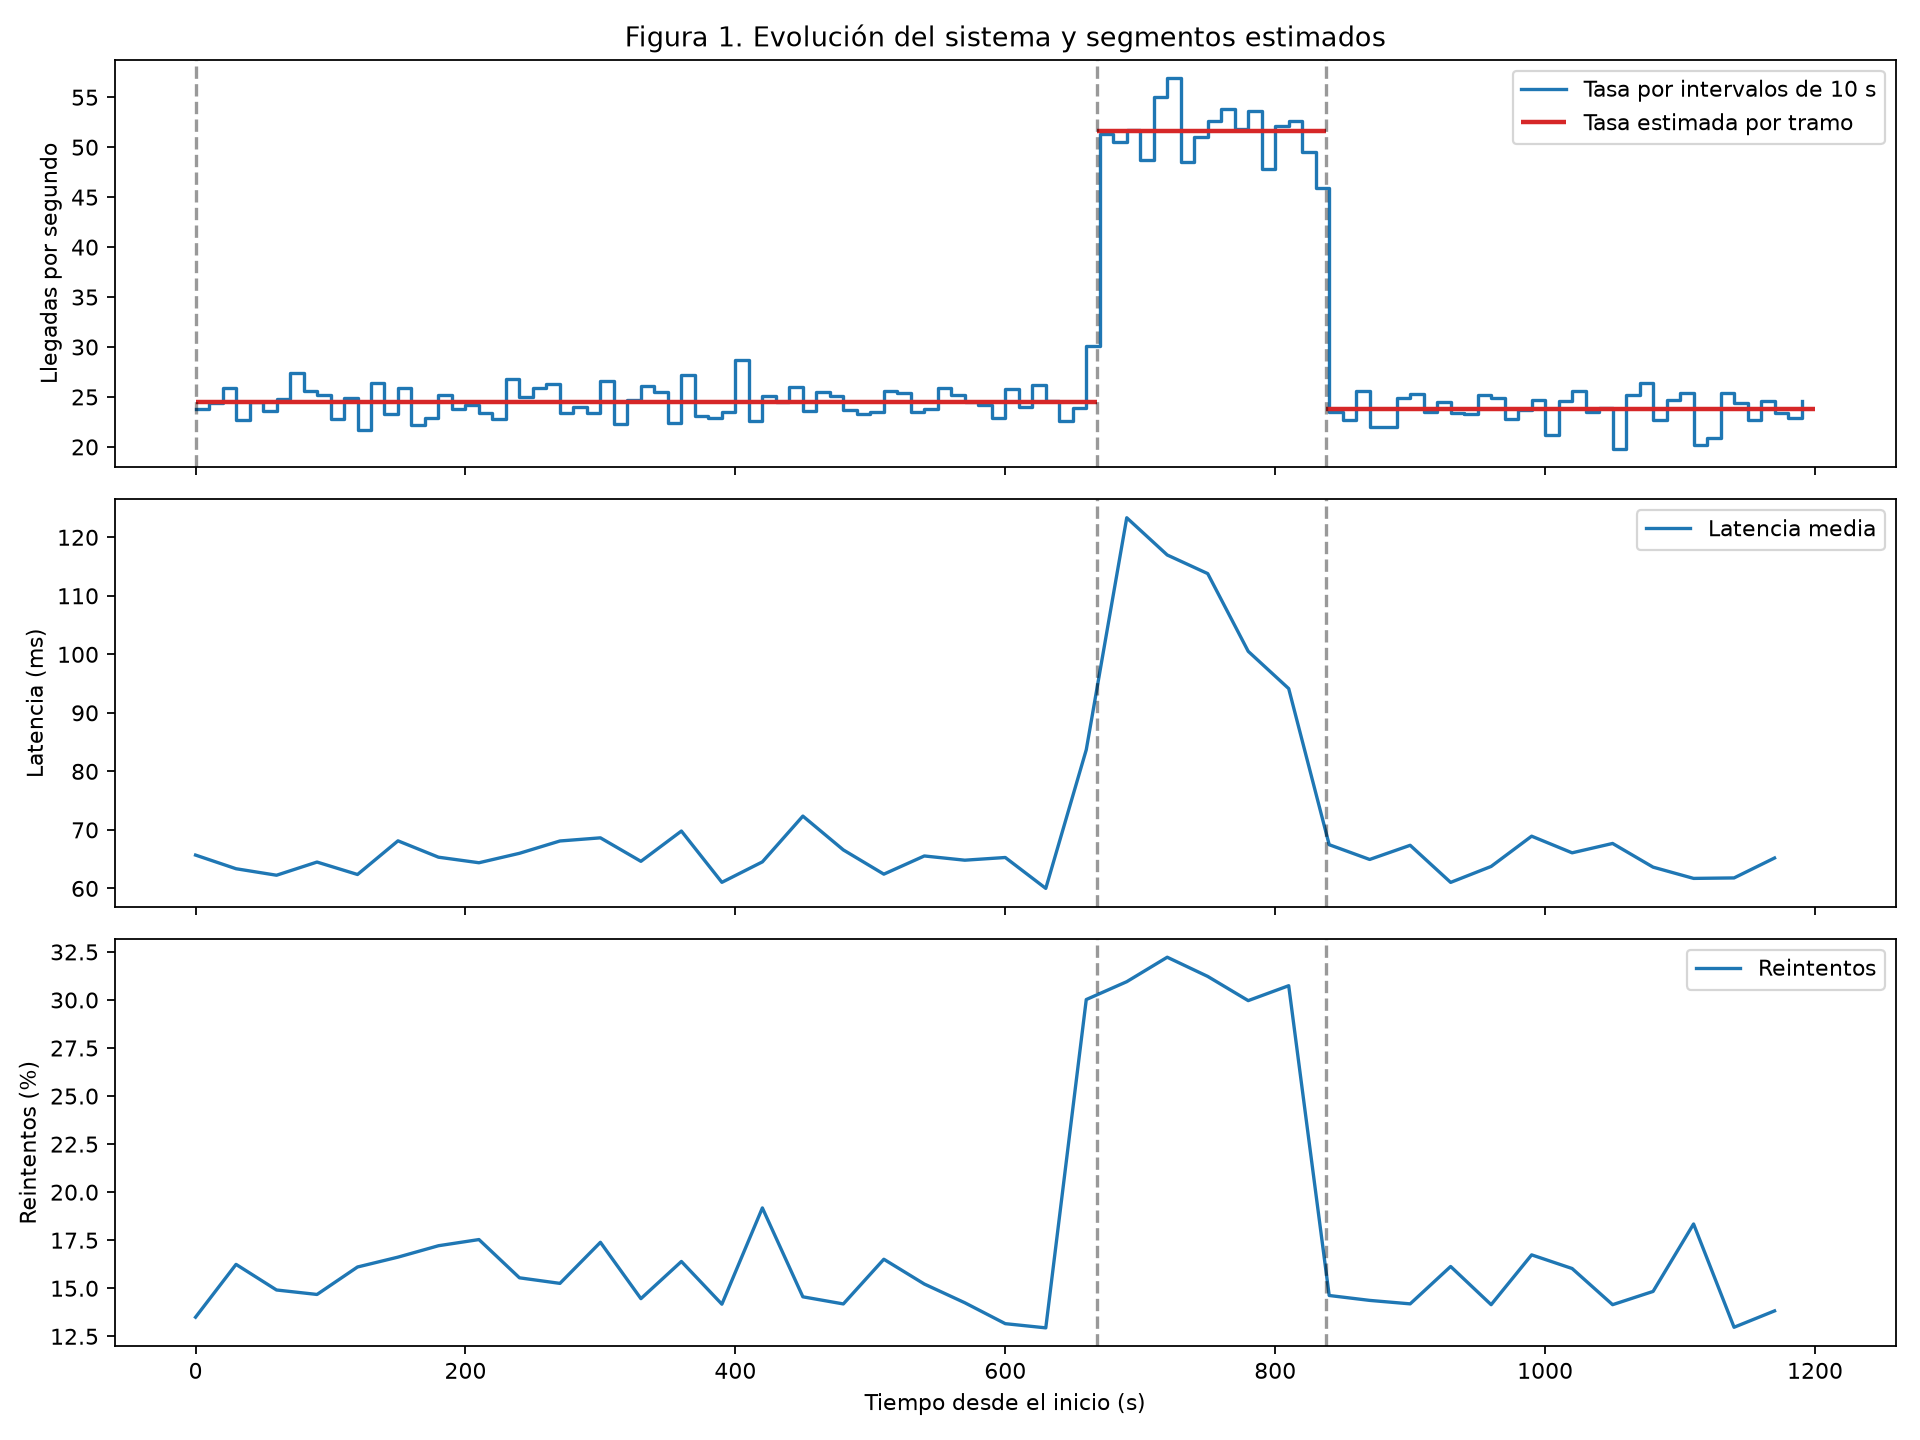

In [20]:
with redirect_stdout(StringIO()):
    segmentar()
display(pd.read_csv(ROOT / "outputs/A2/sensibilidad_segmentacion.csv"))
display(pd.read_csv(ROOT / "outputs/A2/comparacion_tramos_estables.csv"))
figura("A2/figura_1_llegadas.png")


*Figura 1. Tasa de llegadas, latencia y reintentos; los límites deben revisarse para los CSV oficiales del grupo.*

## A3. Estadística descriptiva
La varianza y desviación muestrales usan n−1; la asimetría y el exceso de curtosis se corrigen por sesgo.

**Contexto del bloque.** Calcula y presenta los estadísticos descriptivos de las solicitudes auditadas. Su objetivo es resumir centro, dispersión y forma por versión y régimen.

In [21]:
with redirect_stdout(StringIO()):
    resumen_a3()
display(pd.read_csv(ROOT / "outputs/A3/resumen_descriptivo.csv"))


,regimen,version,variable,n,media,mediana,varianza_muestral,desviacion_muestral,asimetria_corregida,exceso_curtosis_corregido,minimo,maximo,rango,q1,q3,rango_intercuartil
0,carga_alta,A,latencia_ms,4407,106.7,68.01,1.09e+04,104.4,1.864,3.912,15.06,689.7,674.7,31,144.6,113.6
1,carga_alta,A,gpu_ms,4407,31.02,21.08,1510,38.86,2.145,9.585,0,473,473,0,48.28,48.28
2,carga_alta,A,red_ms,4407,29.56,29.63,21.41,4.627,0.02417,-0.0479,13.79,46.37,32.58,26.37,32.73,6.36
3,carga_alta,A,tam_kb,4407,239.6,198.8,2.89e+04,170,1.539,3.947,7.42,1417,1410,116.6,324.7,208.1
4,carga_alta,B,latencia_ms,4374,107.9,68.42,1.105e+04,105.1,1.849,3.981,10.79,700.6,689.8,30.79,148.7,117.9
5,carga_alta,B,gpu_ms,4374,31.53,21.8,1493,38.64,1.688,3.848,0,291.5,291.5,0,49.84,49.84
6,carga_alta,B,red_ms,4374,29.54,29.48,21.37,4.623,0.02998,0.02267,10.79,45.23,34.44,26.39,32.75,6.358
7,carga_alta,B,tam_kb,4374,240.2,202.8,2.841e+04,168.5,1.472,3.423,3.52,1357,1354,117.4,323.9,206.5
8,estable,A,latencia_ms,12411,65.12,53.09,1991,44.62,1.828,5.563,10.91,465.1,454.2,30.63,85.75,55.12
9,estable,A,gpu_ms,12411,31.29,21.58,1493,38.64,1.877,5.875,0,389.7,389.7,0,49.45,49.45


## B. Llegadas, fallos y reintentos
Los intervalos entre llegadas se calculan por separado en cada tramo estable.

**Contexto del bloque.** Ejecuta los cálculos de llegadas, fallos y reintentos con la semilla del grupo y organiza sus resultados en una tabla. Su objetivo es caracterizar el comportamiento del tráfico estable.

In [22]:
import json
with redirect_stdout(StringIO()):
    analizar_b(S)
tabla_resumen(json.loads((ROOT / "outputs/B/resultados.json").read_text(encoding="utf-8")))


,Indicador,Resultado
0,B1 / n,24956
1,B1 / duration_s,1030
2,B1 / rate_s,24.23
3,B1 / confidence,0.95
4,B1 / rate_interval [0],23.93
...,...,...
63,B4 / probability_analytic,0.2293
64,B4 / probability_mc,0.2285
65,B4 / mc_replicas,200000
66,B4 / mc_interval [0],0.2267


# C y D. Tiempos y dependencias

## C1. Distribución mixta del tiempo de GPU
Se comparan la FDA empírica y la lognormal; la identidad de varianza usa divisor n.

**Contexto del bloque.** Calcula la masa en cero, las características de los tiempos positivos y la distribución acumulada mixta de GPU. Su objetivo es comparar la formulación de mezcla con los datos observados.

,Indicador,Resultado
0,n,24956
1,n_cache,10260
2,n_positivos,14696
3,p_cache,0.4111
4,mu_positiva_ms,53.29
5,var_positiva_ddof0_ms2,1366
6,media_modelo_ms,31.38
7,media_empirica_ms,31.38
8,var_modelo_ddof0_ms2,1492
9,var_empirica_ddof0_ms2,1492


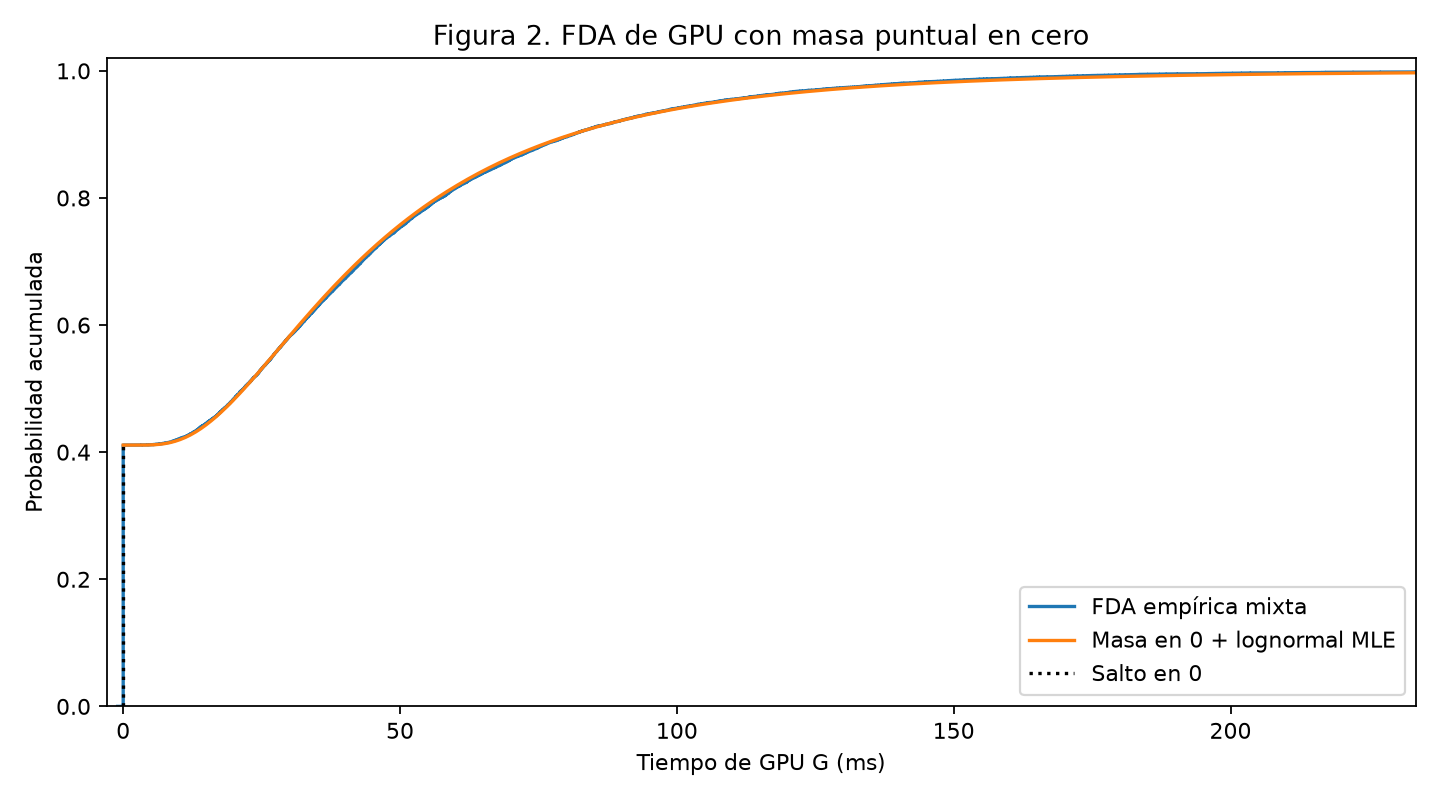

In [23]:
from tiempos_cd import c1
with redirect_stdout(StringIO()):
    resultados_c1 = c1()
tabla_resumen(resultados_c1)
figura("C1/figura_2_fda_gpu.png")


*Figura 2. FDA empírica de GPU y ajuste mixto lognormal, con la masa puntual en cero.*

## C2. Ajuste de la parte positiva de GPU
La log-verosimilitud se optimiza mediante BFGS para Gamma y lognormal; también se calculan distancias KS descriptivas.

**Contexto del bloque.** Ajusta los modelos Gamma y lognormal mediante optimización de sus log-verosimilitudes y presenta los indicadores de ajuste. Su objetivo es comparar ambas descripciones de la parte positiva del tiempo de GPU.

In [24]:
from tiempos_c2 import main as ajustar_c2
with redirect_stdout(StringIO()):
    resultados_c2 = ajustar_c2()
tabla_resumen(resultados_c2)


,Indicador,Resultado
0,n_sin_cache,14696
1,gamma / k,2.526
2,gamma / theta_ms,21.1
3,gamma / log_verosimilitud,-7.033e+04
4,gamma / convergencia,True
5,gamma / mensaje,Optimization terminated successfully.
6,gamma / gradiente_norma,6.526e-09
7,gamma / momentos_k,2.079
8,gamma / momentos_theta_ms,25.63
9,gamma / ks_distancia,0.03976


Compare las distancias KS y las log-verosimilitudes obtenidas con los CSV oficiales; el ajuste marginal no modela por sí solo la relación con el tamaño.

## C3. Tiempo de red
El valor p de KS es nominal porque los parámetros se estiman con la misma muestra. Se muestran por separado la referencia 0,656 y el valor crítico de la versión de SciPy instalada.

**Contexto del bloque.** Resume el tiempo de red, calcula los diagnósticos de distribución y genera la figura correspondiente. Su objetivo es contrastar los datos con la aproximación normal y examinar sus colas.

,Indicador,Resultado
0,n,24956
1,scipy_version,1.18.1
2,media_ms,29.61
3,desviacion_muestral_ms,4.606
4,asimetria_corregida,-0.003898
5,exceso_curtosis_corregido,-0.01929
6,KS_D,0.004553
7,KS_p_nominal_parametros_estimados,0.6773
8,AD_estadistico,0.5911
9,AD_valores_criticos [0],0.561


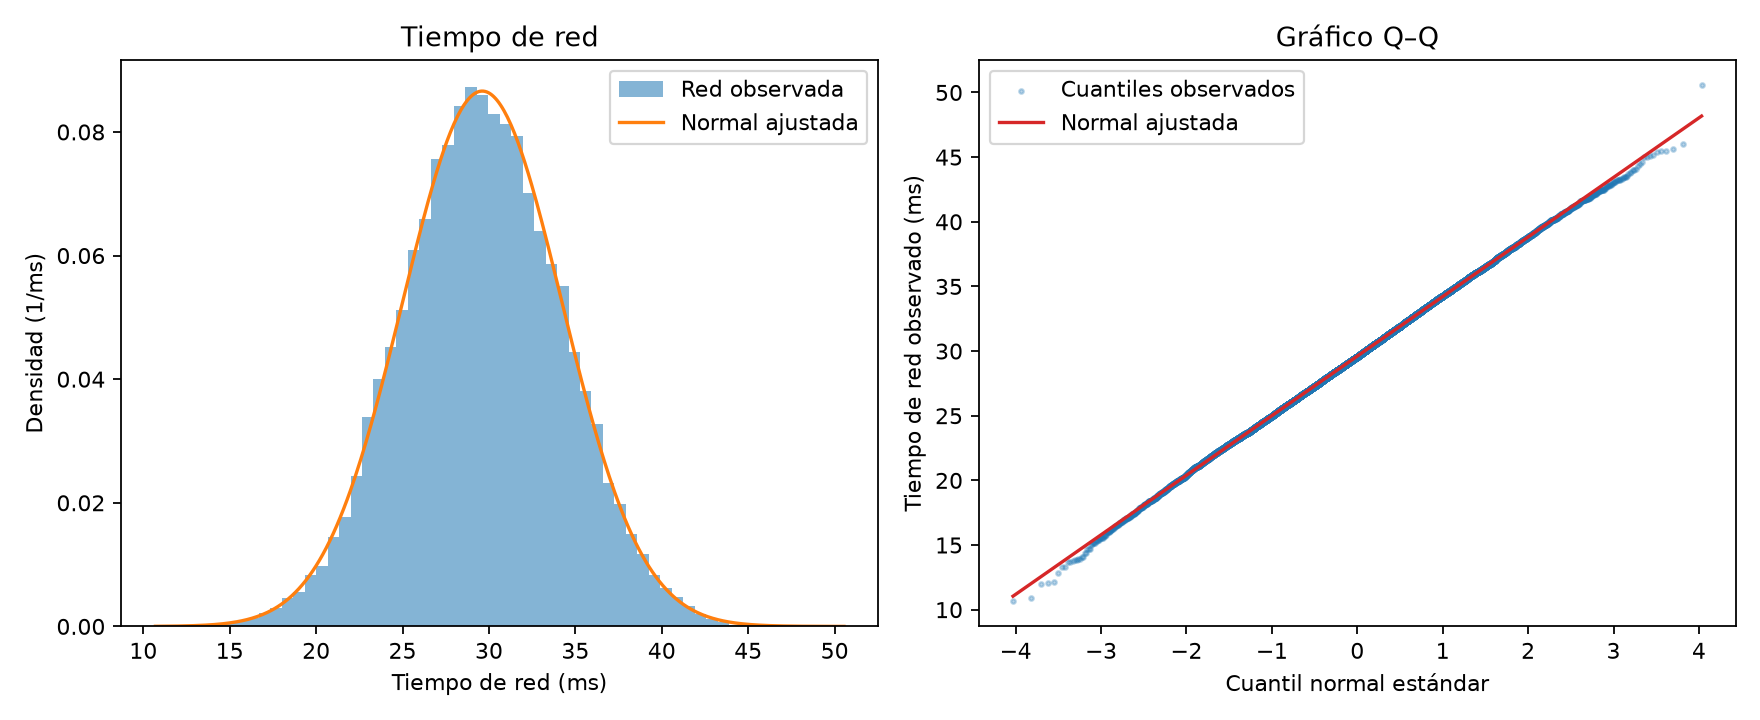

In [25]:
from tiempos_cd import c3
with redirect_stdout(StringIO()):
    resultados_c3 = c3(seed=S)
tabla_resumen(resultados_c3)
figura("C3/figura_3_red.png")


*Figura 3. Distribución del tiempo de red y comparación de cuantiles con la normal.*

## C4. Tiempo acumulado de GPU
Se comparan aproximaciones analíticas con 200.000 bloques de remuestreo independiente con reemplazo.

**Contexto del bloque.** Calcula aproximaciones para la suma de tiempos de GPU y las compara con remuestreo de solicitudes no cacheadas. Su objetivo es evaluar el comportamiento del tiempo acumulado bajo los supuestos usados.

In [26]:
from tiempos_cd import c4
with redirect_stdout(StringIO()):
    resultados_c4 = c4(seed=S)
tabla_resumen(resultados_c4)


,Indicador,Resultado
0,N,14
1,n_positivos,14696
2,media_ms,53.29
3,var_muestral_ms2,1366
4,umbral_ms,956
5,prob_normal,0.06443
6,prob_gamma,0.05555
7,prob_remuestreo_iid,0.07537
8,replicas,200000
9,nivel_confianza,0.95


## D1. Distribución conjunta e independencia
Se calculan las distribuciones conjunta, marginales y condicionales y los intervalos Wald al 95 %.

**Contexto del bloque.** Construye las distribuciones de clase de tamaño y caché, presenta los intervalos condicionales y dibuja el mapa de calor. Su objetivo es examinar su distribución conjunta.

,Indicador,Resultado
0,n,24956
1,marginal_clase / pequeña,0.2046
2,marginal_clase / mediana,0.6841
3,marginal_clase / grande,0.1113
4,marginal_cache / 0,0.5889
5,marginal_cache / 1,0.4111
6,chi_cuadrado,933.3
7,grados_libertad,2
8,p_valor,2.194e-203
9,frecuencia_esperada_minima,1142


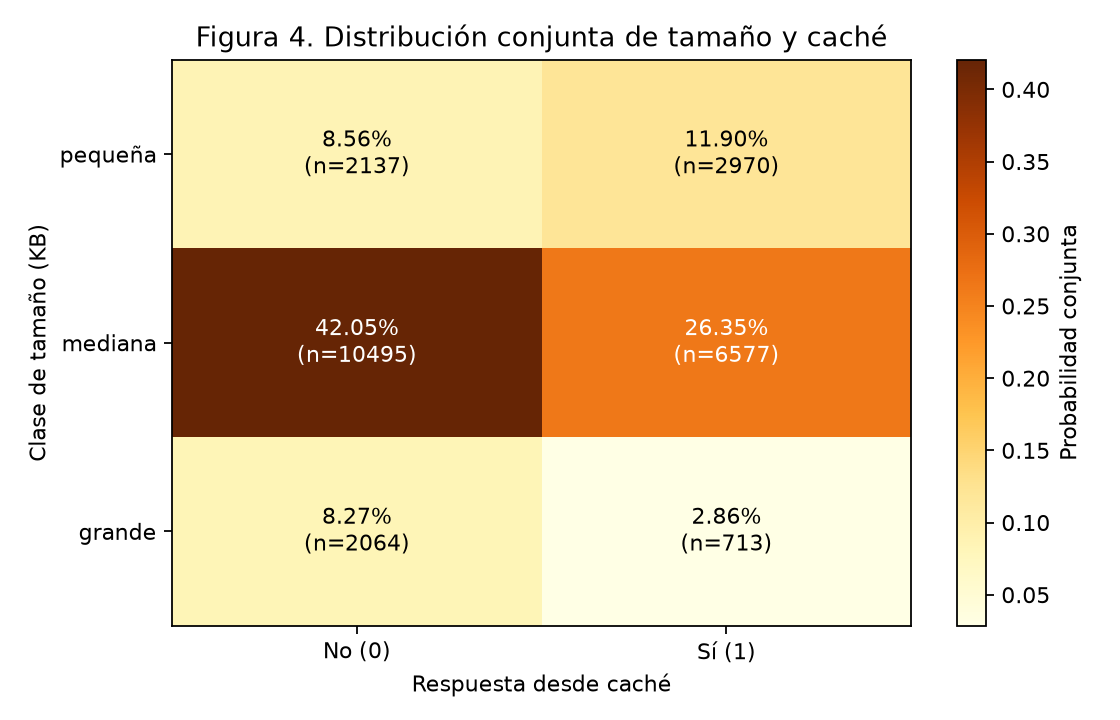

,clase,n,cache_1,proporcion,inferior_wald,superior_wald,nivel_confianza
0,pequeña,5107,2970,0.5816,0.568,0.5951,0.95
1,mediana,17072,6577,0.3853,0.378,0.3926,0.95
2,grande,2777,713,0.2568,0.2405,0.273,0.95


In [27]:
from dependencias_d1 import main as analizar_d1
with redirect_stdout(StringIO()):
    resultados_d1 = analizar_d1()
tabla_resumen(resultados_d1)
figura("D1/figura_4_conjunta.png")
display(pd.read_csv(ROOT / "outputs/D1/intervalos_cache_dada_clase.csv"))


*Figura 4. Distribución conjunta de clase de tamaño y estado de caché; la escala de color representa probabilidad.*

## D2. Esperanza y varianza condicional
Las identidades usan divisor n; la relación con tamaño se resume con 25 grupos por cuantiles y LOWESS con fracción 0,15.

**Contexto del bloque.** Calcula esperanzas y varianzas por grupos y verifica su descomposición en el conjunto observado. Su objetivo es estudiar la relación entre el tamaño de imagen y el tiempo de GPU.

In [28]:
from esperanza_d2 import main as analizar_d2
with redirect_stdout(StringIO()):
    resultados_d2 = analizar_d2()
tabla_resumen(resultados_d2)


,Indicador,Resultado
0,todas / n,24956
1,todas / media_ms,31.38
2,todas / var_empirica_ddof0_ms2,1492
3,todas / var_muestral_ddof1_ms2,1492
4,todas / esperanza_var_condicional_ms2,1181
5,todas / var_esperanza_condicional_ms2,311.1
6,todas / suma_componentes_ms2,1492
7,todas / fraccion_explicada,0.2085
8,todas / comprobacion_media_ms,31.38
9,sin_cache / n,14696


## D3. Regresión matricial y residuos
OLS y WLS con errores clásicos y HC3 e intervalos del 95 % basados en t de Student.

**Contexto del bloque.** Ajusta los modelos OLS y WLS mediante operaciones matriciales y muestra sus intervalos y residuos. Su objetivo es describir la relación entre tamaño y tiempo de GPU y revisar la dispersión de los errores.

,Indicador,Resultado
0,n,14696
1,ols / beta [0],15.1
2,ols / beta [1],0.1453
3,ols / se_clasico [0],0.3938
4,ols / se_clasico [1],0.001244
5,ols / se_hc3 [0],0.4387
6,ols / se_hc3 [1],0.00204
7,ols / max_leverage,0.005069
8,ols / condicion_matriz,3.226e+05
9,wls / beta [0],14.95


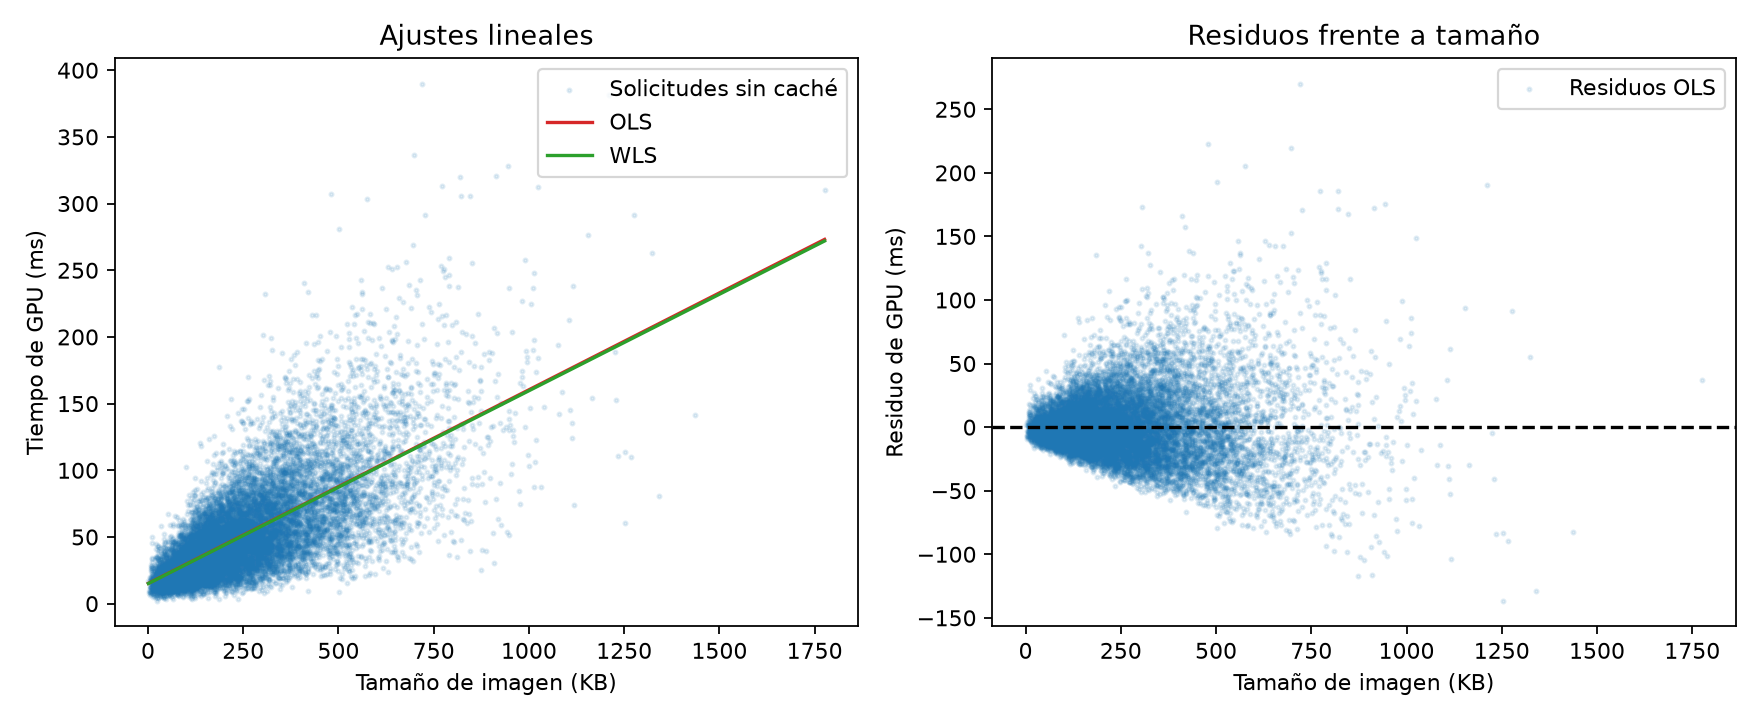

,modelo,coeficiente,estimacion,metodo_se,error_estandar,nivel,critico_t,gl,limite_inferior,limite_superior
0,OLS,intercepto_ms,15.1,clasico,0.3938,0.95,1.96,14694,14.33,15.87
1,OLS,pendiente_ms_por_kb,0.1453,clasico,0.001244,0.95,1.96,14694,0.1428,0.1477
2,OLS,intercepto_ms,15.1,hc3,0.4387,0.95,1.96,14694,14.24,15.96
3,OLS,pendiente_ms_por_kb,0.1453,hc3,0.00204,0.95,1.96,14694,0.1413,0.1493
4,WLS,intercepto_ms,14.95,clasico,0.08296,0.95,1.96,14694,14.79,15.11
5,WLS,pendiente_ms_por_kb,0.1447,clasico,0.001259,0.95,1.96,14694,0.1422,0.1472
6,WLS,intercepto_ms,14.95,hc3,1.011,0.95,1.96,14694,12.97,16.93
7,WLS,pendiente_ms_por_kb,0.1447,hc3,0.00687,0.95,1.96,14694,0.1312,0.1582


In [29]:
from regresion_d3 import main as analizar_d3
with redirect_stdout(StringIO()):
    resultados_d3 = analizar_d3()
tabla_resumen(resultados_d3)
figura("D3/figura_5_regresion.png")
display(pd.read_csv(ROOT / "outputs/D3/intervalos_coeficientes.csv"))


*Figura 5. Ajustes de tiempo de GPU y residuos frente al tamaño de imagen.*

## D4. Covarianza y correlación
Se calculan la covarianza muestral y la correlación de Pearson para solicitudes no cacheadas.

**Contexto del bloque.** Calcula la covarianza y la correlación de Pearson para solicitudes no cacheadas. Su objetivo es medir la asociación lineal entre el tamaño de imagen y el tiempo de GPU.

In [30]:
from dependencias_d4 import main as analizar_d4
with redirect_stdout(StringIO()):
    resultados_d4 = analizar_d4()
tabla_resumen(resultados_d4)


,Indicador,Resultado
0,n,14696
1,covarianza_muestral_kb_ms,4527
2,pearson_r,0.6938
3,pearson_p_numerico,0
4,nota_p,"Si p se imprime como 0, se trata de subdesbord..."
5,r_cuadrado,0.4814


# E, F y G. Monitoreo, inferencia y capacidad

## E. Monitoreo y alertas
Sensibilidad, especificidad, probabilidades posteriores y falsas alarmas. En E3, una frecuencia esperada pequeña limita la aproximación χ².

**Contexto del bloque.** Ejecuta las métricas de detección, Bayes, dependencia condicional y falsas alarmas con los datos de monitoreo. Su objetivo es comparar las reglas de alerta y presentar la figura de falsas alarmas.

### E1

,regla,incidentes,verdaderos_positivos,sin_incidente,falsos_positivos,sensibilidad,sensibilidad_ic_inf,sensibilidad_ic_sup,fpr,fpr_ic_inf,fpr_ic_sup,metodo_ic
0,D1,663,570,5337,68,0.8597,0.8312,0.8841,0.01274,0.01006,0.01612,Wilson 95%
1,D2,663,498,5337,44,0.7511,0.7168,0.7825,0.008244,0.006147,0.01105,Wilson 95%
2,D1_y_D2,663,430,5337,9,0.6486,0.6115,0.684,0.001686,0.0008875,0.003202,Wilson 95%
3,D1_o_D2,663,638,5337,103,0.9623,0.9449,0.9743,0.0193,0.01594,0.02335,Wilson 95%


### E2

,regla,prevalencia_pruebas_observada,prevalencia_produccion,vpp_produccion,vpp_pruebas,vpp_directo,vpp_independencia_hipotetica,diferencia_vpp_independencia_menos_observado
0,D1,0.1105,0.008,0.3524,0.8934,0.8934,NaN,NaN
1,D2,0.1105,0.008,0.4235,0.9188,0.9188,NaN,NaN
2,D1_y_D2,0.1105,0.008,0.7562,0.9795,0.9795,0.9802,0.224
3,D1_o_D2,0.1105,0.008,0.2868,0.861,0.861,0.2715,-0.01526


### E3

,incidente,n,regla,p_observada,p_bajo_independencia,diferencia,chi2,gl,p_valor_chi2,esperado_minimo,chi2_aproximacion_frecuencias_adecuadas
0,0,5337,D1_y_D2,0.001686,0.000105,0.001581,129.8,1,4.638e-30,0.5606,False
1,0,5337,D1_o_D2,0.0193,0.02088,-0.001581,129.8,1,4.638e-30,0.5606,False
2,1,663,D1_y_D2,0.6486,0.6458,0.002798,0.2303,1,0.6313,23.14,True
3,1,663,D1_o_D2,0.9623,0.9651,-0.002798,0.2303,1,0.6313,23.14,True


### E4

,regla,minutos,kmax,fpr,prob_falsa_alarma_minuto,media_falsas_diarias,prob_hasta_k,prob_hasta_k_con_fpr_ic_sup,prob_hasta_k_con_fpr_ic_inf,mc_replicas,mc_prob_hasta_k,mc_ic_inf,mc_ic_sup,condicion
0,D1,1440,6,0.01274,0.01264,18.2,0.0008607,2.477e-05,0.011,200000,0.00086,0.0007408,0.0009984,Binomial: minutos independientes y tasa constante
1,D2,1440,6,0.008244,0.008178,11.78,0.05116,0.004456,0.2266,200000,0.05138,0.05042,0.05236,Binomial: minutos independientes y tasa constante
2,D1_y_D2,1440,6,0.001686,0.001673,2.409,0.9883,0.8217,0.9997,200000,0.9885,0.988,0.989,Binomial: minutos independientes y tasa constante
3,D1_o_D2,1440,6,0.0193,0.01914,27.57,6.948e-07,5.79e-09,3.016e-05,200000,0,0,1.921e-05,Binomial: minutos independientes y tasa constante


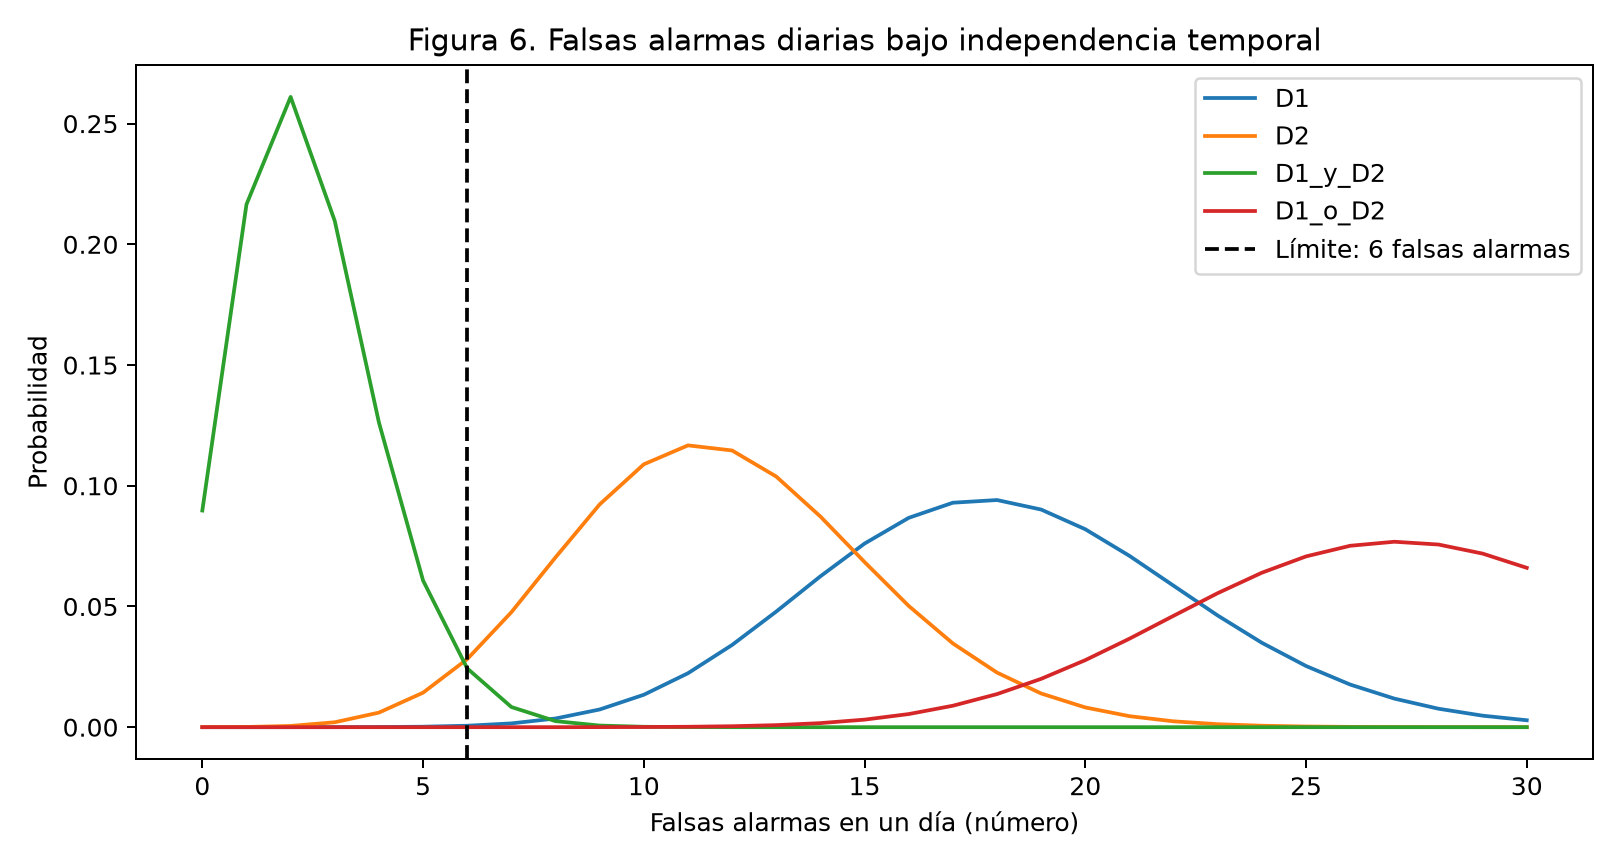

In [31]:
from parte_e import analyze as analizar_e
with redirect_stdout(StringIO()):
    resultados_e = analizar_e(pd.read_csv(ROOT / "data/raw/monitoreo.csv"), seed=S, output_root=ROOT / "outputs")
for punto in ("E1", "E2", "E3", "E4"):
    display(Markdown(f"### {punto}"))
    display(resultados_e[punto])
figura("E4/figura_6_alertas.png")


*Figura 6. Distribución modelada de falsas alarmas por día; las conclusiones dependen de la independencia temporal y de la prevalencia del grupo.*

## F. Inferencia y validación
Los intervalos y coberturas indican su método y nivel en las tablas correspondientes.

**Contexto del bloque.** Ejecuta los análisis de inferencia y validación, lee las tablas generadas y presenta las figuras de cobertura. Su objetivo es cuantificar incertidumbre, comparar versiones y revisar el conjunto de validación.

### F1

,n,replicas,media_poblacion_ms,media_de_medias_ms,desviacion_ms,asimetria,exceso_curtosis,cobertura_ic_normal_z_con_s_muestral,error_mc_cobertura_con_s_muestral,ic_mc_cobertura_inferior,ic_mc_cobertura_superior,nivel_confianza_mc,cobertura_ic_normal_z_con_sigma_empirica,error_mc_cobertura_con_sigma_empirica,umbral_cobertura,criterio_principal,menor_n_evaluado
0,5,20000,65.17,65.16,19.79,0.7458,0.7605,0.8315,0.002647,0.8262,0.8366,0.95,0.9588,0.001405,0.94,normal z con s de cada réplica,200
1,30,20000,65.17,65.23,8.106,0.3621,0.2349,0.9255,0.001857,0.9218,0.9291,0.95,0.9514,0.00152,0.94,normal z con s de cada réplica,200
2,200,20000,65.17,65.18,3.129,0.1155,0.03902,0.9474,0.001578,0.9442,0.9504,0.95,0.9515,0.001519,0.94,normal z con s de cada réplica,200
3,2000,20000,65.17,65.18,0.9917,0.07293,0.01473,0.9495,0.001548,0.9464,0.9524,0.95,0.9497,0.001545,0.94,normal z con s de cada réplica,200


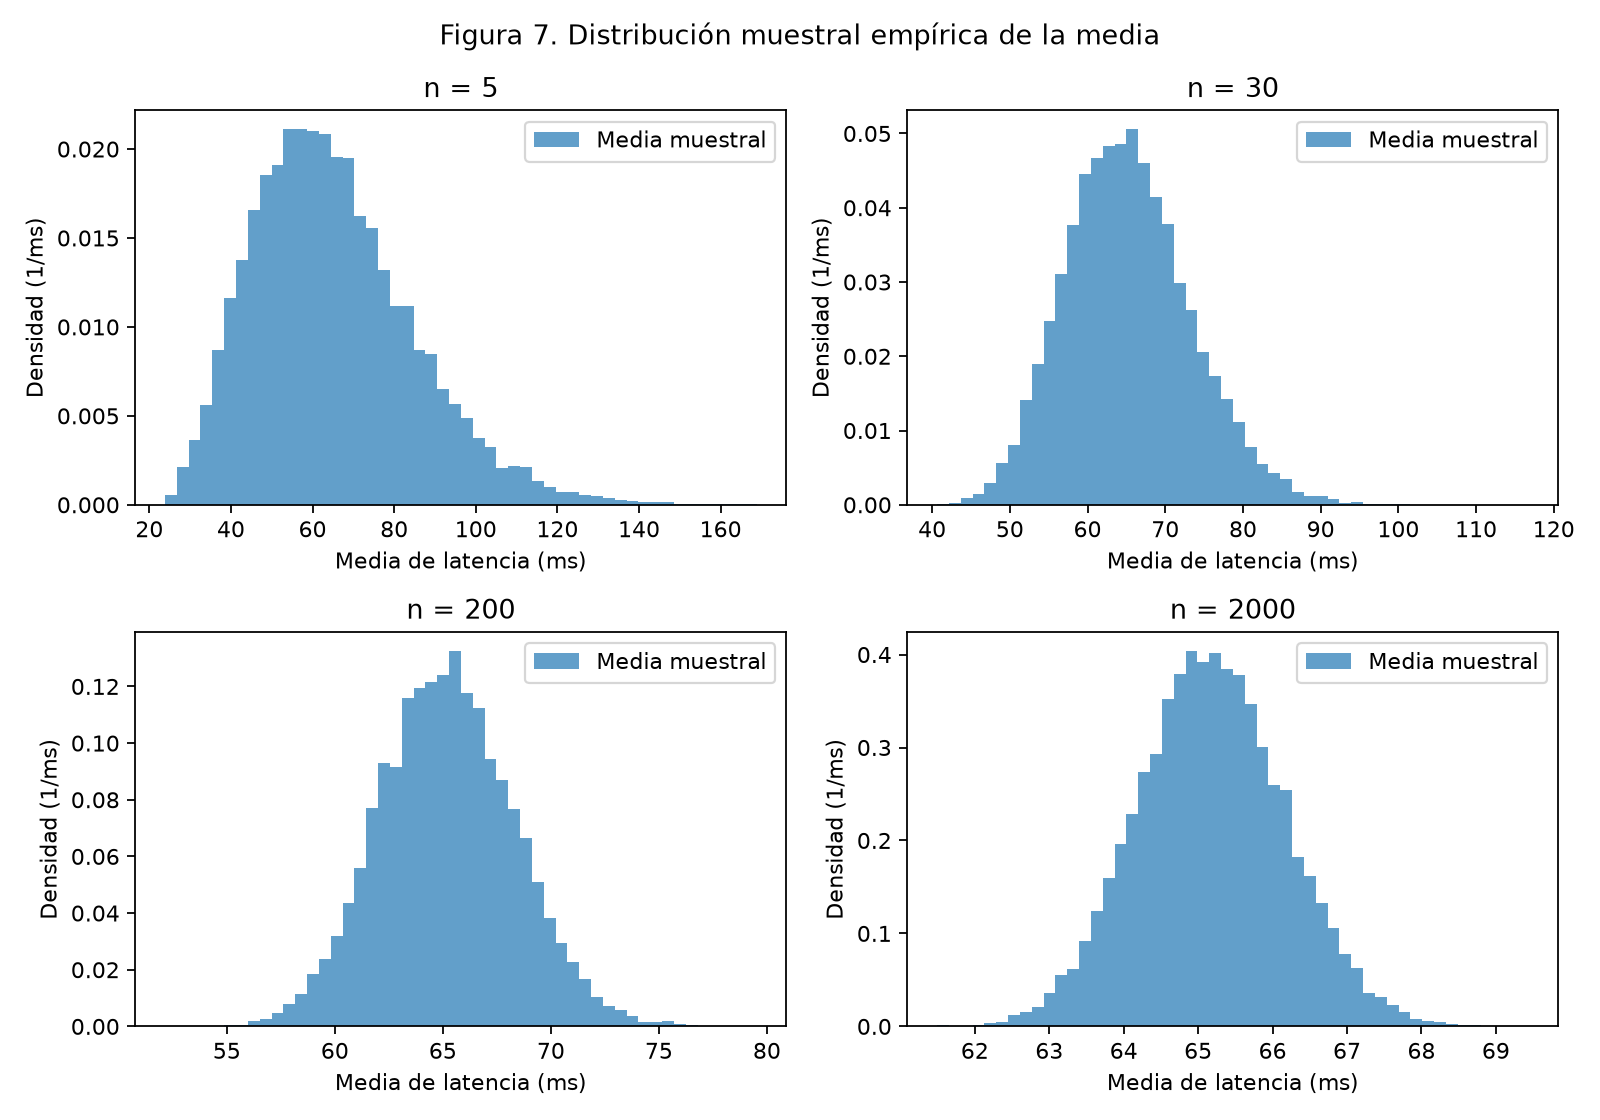

*Figura 7. Distribuciones muestrales de la latencia para varios tamaños de muestra.*

### F2

,metodo,estimacion_ms,inferior_ms,superior_ms,nivel,replicas,longitud_bloque
0,t clásico,65.17,64.62,65.72,0.95,0,0
1,percentiles bootstrap de bloques móviles por t...,65.17,64.43,65.94,0.95,20000,20


### F3

,metrica,n_A,n_B,media_A,media_B,diferencia_B_menos_A,ic_bonferroni_inferior,ic_bonferroni_superior,ic_individual_inferior,ic_individual_superior,nivel_conjunto_minimo,p_sin_ajustar,metodo,error_estandar,gl_welch,critico_z_bonferroni,critico_z_individual
0,GPU sin caché (ms),7325,7371,53.02,53.55,0.5302,-0.9295,1.99,-0.6649,1.725,0.95,0.3845,IC normal z con Bonferroni; p nominal t de Welch,0.6098,1.469e+04,2.394,1.96
1,reintento (>1),12411,12545,0.1498,0.1562,0.006371,-0.004538,0.01728,-0.00256,0.0153,0.95,0.1621,IC normal z con Bonferroni; p nominal t de Welch,0.004557,2.495e+04,2.394,1.96
2,violación SLO >190 ms,12411,12545,0.01845,0.01953,0.001078,-0.003058,0.005215,-0.002308,0.004465,0.95,0.5326,IC normal z con Bonferroni; p nominal t de Welch,0.001728,2.495e+04,2.394,1.96


### F4

,n,p_real,metodo,replicas,cobertura,nivel_nominal,error_mc,cobertura_binomial_exacta
0,20,0.01,Wald,10000,0.1782,0.95,0.003827,0.1821
1,20,0.01,Wilson,10000,0.983,0.95,0.001293,0.9831
2,20,0.05,Wald,10000,0.6285,0.95,0.004832,0.6389
3,20,0.05,Wilson,10000,0.9266,0.95,0.002608,0.9245
4,20,0.15,Wald,10000,0.8213,0.95,0.003831,0.8185
5,20,0.15,Wilson,10000,0.9786,0.95,0.001447,0.9781
6,20,0.5,Wald,10000,0.9536,0.95,0.002103,0.9586
7,20,0.5,Wilson,10000,0.9536,0.95,0.002103,0.9586
8,50,0.01,Wald,10000,0.3956,0.95,0.00489,0.3948
9,50,0.01,Wilson,10000,0.9076,0.95,0.002896,0.9106


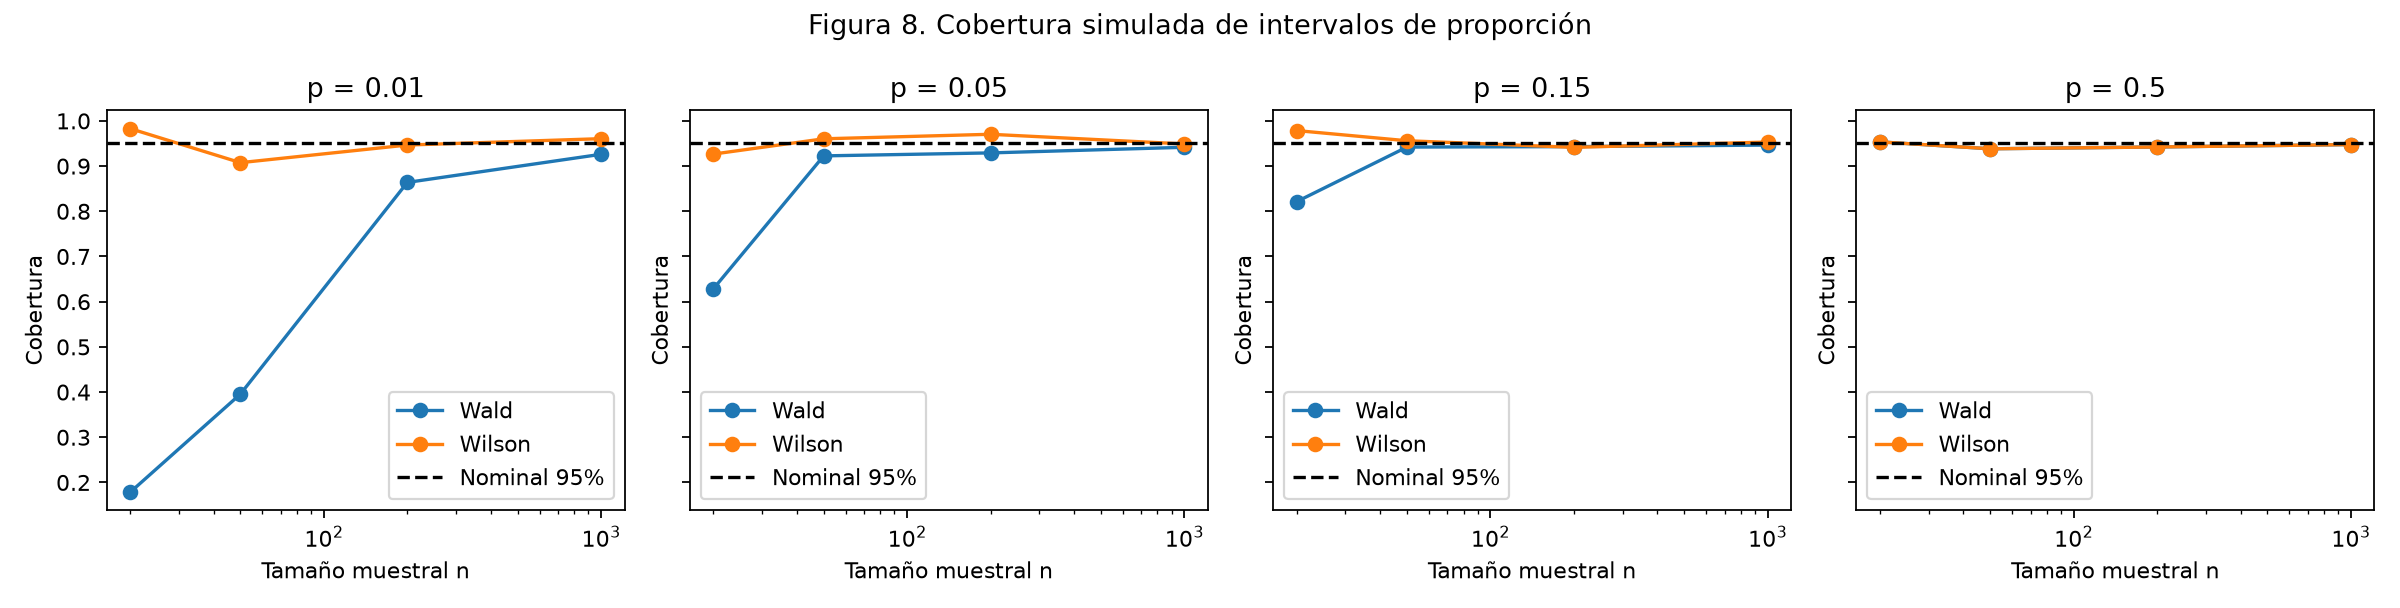

*Figura 8. Cobertura de intervalos de proporción para distintos tamaños y probabilidades.*

### F5

,metodo,n_por_version,varianza_A_ms2,varianza_B_ms2,semiancho_proyectado_ms,replicas,media_semiancho_simulado_ms,fraccion_semiancho_menor_igual_1,cobertura_simulada
0,individual,10495,1378,1354,1,1000,1,0.505,0.945
1,Bonferroni 3 métricas,15658,1378,1354,1,1000,0.9992,0.524,0.978


### F6

,parametro,base,validacion,diferencia
0,n,2.496e+04,2.948e+04,4529
1,tasa_llegadas_s,24.23,24.57,0.3417
2,p_cache,0.4111,0.4101,-0.0009828
3,media_gpu_no_cache_ms,53.29,53.11,-0.1761
4,media_red_ms,29.61,29.59,-0.01786
5,media_latencia_ms,65.17,65.25,0.07919
6,p_slo,0.01899,0.01896,-3.464e-05
7,p_fallo_intento,0.1533,0.2047,0.05138
8,p_reintento,0.153,0.2047,0.05169


In [32]:
from parte_f import main as analizar_f
with redirect_stdout(StringIO()):
    analizar_f(seed=S)
for punto, archivo in [("F1", "distribucion_muestral_F1.csv"),
                       ("F2", "ic_latencia_F2.csv"),
                       ("F3", "comparacion_AB_F3.csv"),
                       ("F4", "cobertura_wald_wilson_F4.csv"),
                       ("F5", "tamano_muestral_F5.csv"),
                       ("F6", "comparacion_validacion_F6.csv")]:
    display(Markdown(f"### {punto}"))
    display(pd.read_csv(ROOT / "outputs" / punto / archivo))
    if punto == "F1":
        figura("F1/figura_7_tcl_latencia.png")
        display(Markdown("*Figura 7. Distribuciones muestrales de la latencia para varios tamaños de muestra.*"))
    if punto == "F4":
        figura("F4/figura_8_cobertura_proporciones.png")
        display(Markdown("*Figura 8. Cobertura de intervalos de proporción para distintos tamaños y probabilidades.*"))


Interprete las diferencias e intervalos de F3 y la validación de F6 a partir de las tablas calculadas con los CSV oficiales.

## G1 y G2. Simulación de capacidad
G1 contrasta el simulador con la muestra histórica. G2 evalúa el SLO mediante el límite superior del intervalo de simulación.

**Contexto del bloque.** Contrasta el simulador con la operación histórica y proyecta distintas capacidades, mostrando tablas y figura. Su objetivo es evaluar la sensibilidad de la violación del SLO al número de GPU.

,metrica,observado,simulado,ic_inferior,ic_superior,nivel_confianza,diferencia_simulado_menos_observado,replicas
0,mediana_ms,53.2,53.16,53,53.33,0.95,-0.0417,20
1,p95_ms,152.2,152.6,151.9,153.3,0.95,0.3776,20
2,proporcion_mayor_190_ms,0.01899,0.02129,0.02083,0.02174,0.95,0.002295,20


,gpus,rho,violacion,ic_inferior,ic_superior,nivel_confianza,replicas,duracion_s,calentamiento_s,estable_rho_menor_1
0,1,1.148,0.5886,0.5874,0.5897,0.95,30,600,30,False
1,2,0.5739,0.04575,0.04414,0.04736,0.95,30,600,30,True
2,3,0.3826,0.01578,0.01544,0.01611,0.95,30,600,30,True
3,4,0.287,0.01393,0.01361,0.01425,0.95,30,600,30,True
4,5,0.2296,0.01367,0.01338,0.01396,0.95,30,600,30,True


### Contraste M/M/c: espera por GPU antes de incluir red

,gpus,rho,probabilidad_espera,espera_media_ms,estable
0,1,1.148,NaN,NaN,False
1,2,0.5739,0.4186,26.35,True
2,3,0.3826,0.127,3.678,True
3,4,0.287,0.0321,0.6037,True
4,5,0.2296,0.006838,0.09521,True


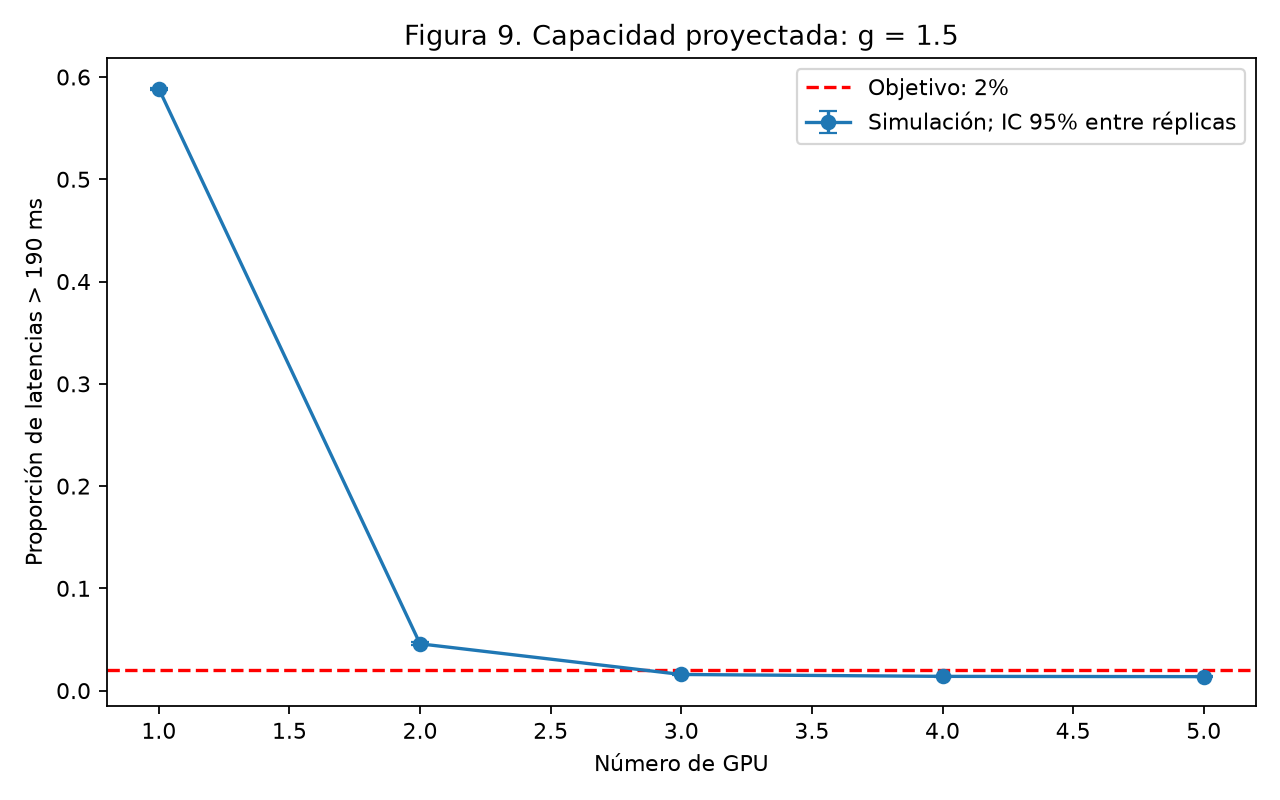

In [33]:
from parte_g import main as simular_g
with redirect_stdout(StringIO()):
    resultados_g = simular_g(seed=S)
display(pd.DataFrame(resultados_g[0]))
display(resultados_g[1])
display(Markdown("### Contraste M/M/c: espera por GPU antes de incluir red"))
display(pd.read_csv(ROOT / "outputs/G3/contraste_mmc_parcial.csv"))
figura("G2/figura_9_capacidad_slo.png")


*Figura 9. Violaciones proyectadas del SLO por capacidad, con intervalos del 95 % entre réplicas.*

## G3. Robustez de capacidad
Se evalúan 200 escenarios, con cinco réplicas por capacidad y 400 s totales por réplica, incluidos 20 s de calentamiento. G3 usa la estimación puntual; G2 usa el límite superior del intervalo.

**Contexto del bloque.** Genera escenarios paramétricos y evalúa varias capacidades mediante réplicas de simulación. Su objetivo es resumir la variabilidad de la capacidad seleccionada y compararla con un modelo simplificado.

In [34]:
import pandas as pd
from IPython.display import display
from parte_g import ejecutar_g3

datos_g3 = pd.read_csv(ROOT / "outputs/A1/solicitudes_auditadas.csv")
tiempos_g3 = datos_g3.t_llegada_s
estable_g3 = datos_g3[((tiempos_g3 >= 0) & (tiempos_g3 < 668)) |
                      ((tiempos_g3 >= 838) & (tiempos_g3 <= 1200))]
escenarios_g3, detalles_g3, distribucion_g3, resumen_g3 = ejecutar_g3(
    estable_g3, seed=S, n_escenarios=200, replicas=5, duracion_s=400,
    calentamiento_s=20, capacidades=(2, 3, 4, 5),
    umbral_ms=tau_ms, epsilon=epsilon, crecimiento=g)
display(Markdown("### Distribución de capacidad mínima por escenario"))
display(distribucion_g3)
display(Markdown("### Cumplimiento por capacidad y contraste M/M/c"))
display(resumen_g3)

### Distribución de capacidad mínima por escenario

,capacidad,escenarios,proporcion,ic_mc_inferior,ic_mc_superior,nivel_confianza
0,2,0,0,0,0.01885,0.95
1,3,200,1,0.9812,1,0.95
2,4,0,0,0,0.01885,0.95
3,5,0,0,0,0.01885,0.95
4,sin capacidad en la rejilla,0,0,0,0.01885,0.95


### Cumplimiento por capacidad y contraste M/M/c

,gpus,prob_cumplimiento,escenarios,violacion_media,rho_media,violacion_media_mmc,prob_cumplimiento_mmc,escenarios_inestables_mmc,ic_mc_inferior,ic_mc_superior,nivel_confianza
0,2,0,200,0.04523,0.5748,0.07667,0,0,0,0.01885,0.95
1,3,1,200,0.01584,0.3832,0.03383,0,0,0.9812,1,0.95
2,4,1,200,0.01405,0.2874,0.03025,0,0,0.9812,1,0.95
3,5,1,200,0.01376,0.2299,0.0298,0,0,0.9812,1,0.95


Interprete la capacidad de G2 y G3 con los nuevos parámetros, considerando la discrepancia de validación y el contraste M/M/c; los resultados dependen de los supuestos del modelo.

## G4. Memorando ejecutivo
El memorando presenta los resultados y las limitaciones relevantes para la decisión operativa.

**Contexto del bloque.** Construye el memorando ejecutivo en Markdown y PDF a partir de los resultados calculados. Su objetivo es reunir los hallazgos y límites relevantes para la dirección técnica.

In [35]:
from memorando_g4 import main as generar_memorando
with redirect_stdout(StringIO()):
    memoria_g4 = generar_memorando()
display(Markdown("Se generó el memorando ejecutivo en Markdown y PDF."))


Se generó el memorando ejecutivo en Markdown y PDF.

## Archivos generados

**Contexto del bloque.** Copia las salidas generadas desde el entorno temporal a una carpeta nueva del directorio de trabajo. Su objetivo es conservar las tablas, figuras y el memorando después de ejecutar el cuaderno.

In [36]:
import shutil
import tempfile

destino_resultados = Path(tempfile.mkdtemp(prefix="resultados_andes_", dir=Path.cwd()))
shutil.copytree(ROOT / "outputs", destino_resultados / "outputs")
display(Markdown(f"**Resultados generados:** `{destino_resultados / 'outputs'}`"))


**Verificaci?n:** la ejecuci?n aislada gener? las salidas correctas. La pr?xima ejecuci?n crear? una nueva carpeta de resultados.